# Telco Churn — Trực quan hóa **bất định** theo Chương 16 (Claus Wilke)

**Câu hỏi nhỏ để thuyết trình:** *“Churn rate ước lượng có đáng tin đến đâu, và bất định thay đổi cách ta chọn nhóm ưu tiên giữ chân như thế nào?”*

- Dataset gốc: **Kaggle — Telco Customer Churn** (`blastchar/telco-customer-churn`), 7.043 khách hàng, 21 cột.
- Chương tham chiếu: Claus O. Wilke, **Chapter 16 — Visualizing uncertainty**.
- Phạm vi: tập trung vào **Contract, PaymentMethod, tenure** và `Churn`.
- Lưu ý: đây là dữ liệu quan sát. Ta nói **“liên quan đến churn”**, không khẳng định một biến *gây ra* churn.


Các biểu đồ còn lại là **appendix/demo** để gần như bao phủ toàn bộ nhóm biểu đồ của Chương 16.

Nguồn:
- https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- https://clauswilke.com/dataviz/visualizing-uncertainty.html

## 0. Cài thư viện và đọc dữ liệu

Notebook ưu tiên đọc file CSV nằm cùng thư mục. Nếu không có, nó thử tải từ một GitHub mirror của cùng bộ dữ liệu — tiện khi chạy trên Colab/Kaggle.

In [ ]:
# Nếu môi trường thiếu thư viện, bỏ comment dòng dưới:
# !pip install pandas numpy matplotlib scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm, beta, gaussian_kde
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

warnings.filterwarnings('ignore')

# -----------------------------
# Style đơn giản, thống nhất
# -----------------------------
plt.rcParams.update({
    'figure.figsize': (9, 4.8),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
    'axes.titlesize': 13,
    'axes.labelsize': 10.5,
    'font.size': 10.5,
})

BLUE = plt.cm.Blues(0.90)
MID = plt.cm.Blues(0.65)
LIGHT = plt.cm.Blues(0.38)
PALE = plt.cm.Blues(0.20)
GRAY = '0.45'
RED = '#b23a48'

RNG = np.random.default_rng(42)

LOCAL_FILE = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
MIRROR_URL = 'https://raw.githubusercontent.com/aiplanethub/Datasets/master/WA_Fn-UseC_-Telco-Customer-Churn.csv'

if os.path.exists(LOCAL_FILE):
    df = pd.read_csv(LOCAL_FILE)
    source_used = LOCAL_FILE
else:
    df = pd.read_csv(MIRROR_URL)
    source_used = MIRROR_URL

print('Nguồn đã đọc:', source_used)
print('Kích thước:', df.shape)
df.head()

Nguồn đã đọc: https://raw.githubusercontent.com/aiplanethub/Datasets/master/WA_Fn-UseC_-Telco-Customer-Churn.csv
Kích thước: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Làm sạch tối thiểu

- `TotalCharges` có một số giá trị trắng → đổi sang số, cho `NaN`.
- `Churn` đổi thành 0/1 để tính tỷ lệ.
- Giữ nguyên dữ liệu phân loại vì ta chủ yếu trực quan hóa tỷ lệ churn theo nhóm.

In [ ]:
df = df.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['Churn_bin'] = (df['Churn'] == 'Yes').astype(int)

print('Thiếu TotalCharges:', df['TotalCharges'].isna().sum())
print('Số khách hàng:', len(df))
print(f"Churn rate toàn bộ mẫu: {df['Churn_bin'].mean():.1%}")

Thiếu TotalCharges: 11
Số khách hàng: 7043
Churn rate toàn bộ mẫu: 26.5%


## 2. Hàm hỗ trợ: Wilson CI, bootstrap và posterior Beta

Ta dùng **Wilson interval** cho tỷ lệ churn vì ổn định hơn khoảng `p ± 1.96×SE` khi tỷ lệ gần 0/1 hoặc nhóm nhỏ.

In [ ]:
def wilson_ci(successes, n, confidence=0.95):
    """Wilson confidence interval cho một tỷ lệ."""
    if n == 0:
        return np.nan, np.nan
    z = norm.ppf(1 - (1-confidence)/2)
    p = successes / n
    den = 1 + z*z/n
    center = (p + z*z/(2*n)) / den
    half = z*np.sqrt((p*(1-p)/n) + z*z/(4*n*n)) / den
    return center-half, center+half


def rate_summary(data, group_col, confidence=0.95):
    rows = []
    for name, g in data.groupby(group_col, dropna=False):
        n = len(g)
        s = int(g['Churn_bin'].sum())
        p = s/n
        lo, hi = wilson_ci(s, n, confidence)
        rows.append([name, n, s, p, lo, hi])
    return pd.DataFrame(rows, columns=[group_col, 'n', 'churned', 'rate', 'lo', 'hi'])


def bootstrap_rate(values, B=4000, seed=42):
    """Với dữ liệu Bernoulli, empirical bootstrap của số success ~ Binomial(n, p_hat)."""
    values = np.asarray(values, dtype=int)
    n = len(values)
    p = values.mean()
    rng = np.random.default_rng(seed)
    return rng.binomial(n, p, size=B) / n


def bootstrap_mean(values, B=3000, seed=42):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(B, len(values)))
    return values[idx].mean(axis=1)


def beta_posterior(successes, n, a0=1, b0=1):
    """Posterior Beta với prior Beta(1,1) mặc định."""
    return a0 + successes, b0 + (n-successes)

In [ ]:
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

# Phần A — Framing probabilities as frequencies

## Biểu đồ 1 — Frequency framing (Figure 16.1)

**Có thể dùng trong Telco:**
- “Trong 100 khách tương tự, khoảng bao nhiêu người rời dịch vụ?”
- So trực quan churn của Month-to-month với Two year.
- Biến xác suất từ một con số trừu tượng thành số khách hàng cụ thể.

**Ví dụ vẽ:** So trực quan khách hàng rời đi của Month-to-month với Two year .

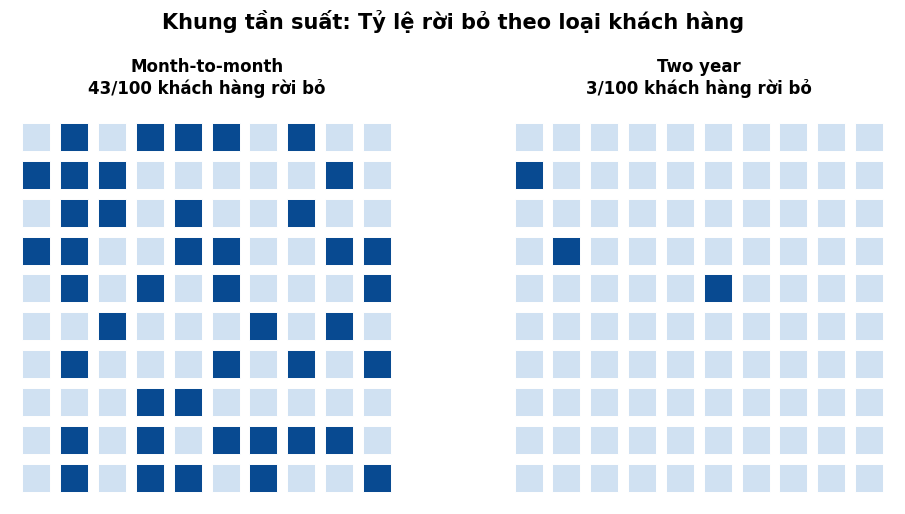

Month-to-month: 42.7% ≈ 43/100 khách hàng rời bỏ.
Two year: 2.8% ≈ 3/100 khách hàng rời bỏ.

KẾT LUẬN: Trong mẫu dữ liệu, khách hàng Month-to-month có tỷ lệ churn cao hơn rõ rệt so với khách hàng Two year.


In [ ]:
# =========================================================
# FREQUENCY FRAMING: MONTH-TO-MONTH vs TWO-YEAR
# Lưới 10 x 10
# =========================================================

M2M = df[df["Contract"] == "Month-to-month"]
TWO = df[df["Contract"] == "Two year"]

p_m2m = M2M["Churn_bin"].mean()
p_two = TWO["Churn_bin"].mean()


def draw_frequency_frame(ax, p, title, color=BLUE):
    n_churn = int(round(100 * p))

    flags = np.array(
        [1] * n_churn +
        [0] * (100 - n_churn)
    )

    # Cố định để biểu đồ không thay đổi mỗi lần chạy
    rng = np.random.default_rng(42)
    rng.shuffle(flags)

    # 10 cột × 10 hàng
    for i, f in enumerate(flags):
        x = i % 10
        y = 9 - i // 10

        ax.scatter(
            x,
            y,
            s=400,
            marker="s",
            color=color if f else PALE,
            edgecolor="white",
            linewidth=0.7
        )

    ax.set_xlim(-0.7, 9.7)
    ax.set_ylim(-0.7, 9.7)

    # Quan trọng: giữ tỷ lệ 1:1
    # => khoảng cách giữa hàng = khoảng cách giữa cột
    ax.set_aspect("equal")

    ax.axis("off")

    ax.set_title(
        f"{title}\n{n_churn}/100 khách hàng rời bỏ",
        fontsize=12,
        fontweight="bold",
        pad=12
    )


# =========================================================
# FIGURE
# =========================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 5)
)

draw_frequency_frame(
    axes[0],
    p_m2m,
    "Month-to-month"
)

draw_frequency_frame(
    axes[1],
    p_two,
    "Two year"
)

fig.suptitle(
    "Khung tần suất: Tỷ lệ rời bỏ theo loại khách hàng",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()


# =========================================================
# KẾT LUẬN
# =========================================================

n_m2m = int(round(100 * p_m2m))
n_two = int(round(100 * p_two))

print(
    f"Month-to-month: {p_m2m:.1%} "
    f"≈ {n_m2m}/100 khách hàng rời bỏ."
)

print(
    f"Two year: {p_two:.1%} "
    f"≈ {n_two}/100 khách hàng rời bỏ."
)

print(
    "\nKẾT LUẬN: Trong mẫu dữ liệu, khách hàng Month-to-month "
    "có tỷ lệ churn cao hơn rõ rệt so với khách hàng Two year."
)

## Biểu đồ 2 — Quantile dot plot (Figure 16.3)

**Có thể dùng trong Telco:**
- 10 chấm = 10 kết quả đại diện, mỗi chấm khoảng 10% khối xác suất.
- Dễ nói khi thuyết trình hơn một density curve liên tục.

**Ví dụ vẽ:** 10 quantile của phân phối chênh lệch tỷ lệ rời bỏ giữa nam và nữ

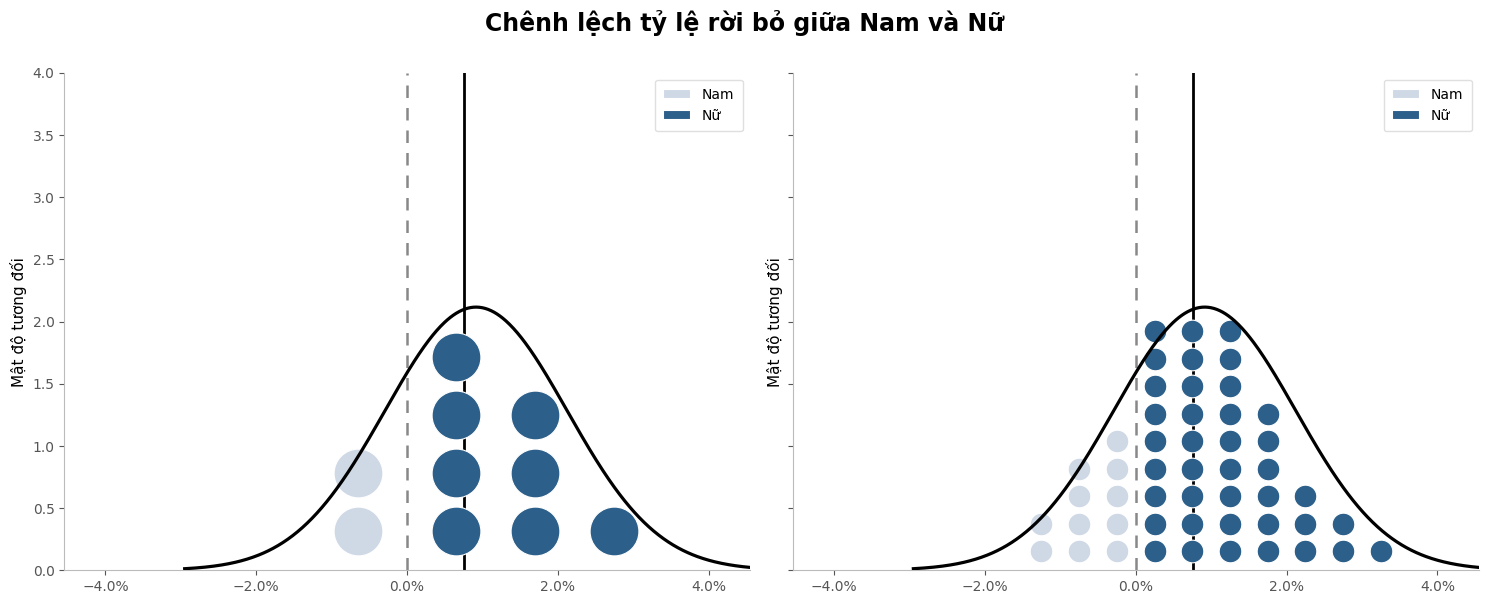

Tỷ lệ rời bỏ nữ: 27.0%
Tỷ lệ rời bỏ nam: 26.2%
Chênh lệch nam - nữ: +0.8%
95% bootstrap interval: [-1.3%, +2.9%]

Khách hàng nam rời bỏ cao hơn: 23.1%
Khách hàng nữ rời bỏ cao hơn: 76.9%

Normal curve được tạo từ panel 1:
mu = 0.0092
sigma = 0.0121

KẾT LUẬN: Nữ có tỷ lệ rời bỏ trong mẫu cao hơn nam một chút, nhưng phân phối bootstrap vẫn nằm ở cả hai phía của 0. Vì vậy khác biệt giữa hai nhóm chưa rõ ràng.


In [ ]:
# =========================================================
# GENDER — 10 DOTS vs 50 DOTS (compact)
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

# ----- 0. THAM SỐ -----
COL_GAP_10, ROW_GAP_10, DOT_SIZE_10, Y_START_10 = 0.0105, 0.88, 0.80, 0.60
COL_GAP_50, ROW_GAP_50, DOT_SIZE_50, Y_START_50 = 0.0050, 0.88, 0.78, 0.60
CURVE_HEIGHT, CURVE_WIDTH, TAIL_SIGMA, Y_MAX = 1.10, 1.15, 3.2, 4.0

# ----- 1. DATA -----
female = df.loc[df["gender"] == "Female", "Churn_bin"].to_numpy()
male   = df.loc[df["gender"] == "Male",   "Churn_bin"].to_numpy()

# ----- 2. BOOTSTRAP -----
rng = np.random.default_rng(42); B = 5000; boot_diff = np.empty(B)
for i in range(B):
    sf = rng.choice(female, size=len(female), replace=True)
    sm = rng.choice(male,   size=len(male),   replace=True)
    boot_diff[i] = sf.mean() - sm.mean()

# ----- 3. SUMMARY -----
p_female, p_male = female.mean(), male.mean()
best_estimate = p_female - p_male
lo95, hi95 = np.quantile(boot_diff, [0.025, 0.975])
area_left  = np.mean(boot_diff < 0)
area_right = np.mean(boot_diff > 0)

# ----- 4. X LIMIT -----
q_lo, q_hi = np.quantile(boot_diff, [0.001, 0.999])
X_LIMIT = max(abs(q_lo), abs(q_hi), 0.04) + 0.005

# ----- 5. COLORS -----
MALE_C   = "#cfd9e6"   # xanh nhạt — Male
FEMALE_C = "#2c5f8a"   # xanh đậm  — Female

# ----- 6. BASE PANEL -----
def draw_base_panel(ax):
    ax.axvline(0, color="#888888", linestyle=(0, (5, 4)), linewidth=1.8, zorder=1)
    ax.axvline(best_estimate, color="black", linewidth=2, zorder=1)
    ax.set_xlim(-X_LIMIT, X_LIMIT); ax.set_ylim(0, Y_MAX)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylabel("Mật độ tương đối", fontsize=11)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#bbbbbb"); ax.spines["bottom"].set_color("#bbbbbb")
    ax.tick_params(axis="both", colors="#555555", labelsize=10)

# ----- 7. GAP -> DY -----
def get_equal_dy(ax, col_gap):
    ax.figure.canvas.draw()
    p0 = ax.transData.transform((0, 0)); px = ax.transData.transform((col_gap, 0))
    pixel_gap = abs(px[0] - p0[0]); py = p0 + np.array([0, pixel_gap])
    inv = ax.transData.inverted(); y0 = inv.transform(p0)[1]; y1 = inv.transform(py)[1]
    return abs(y1 - y0)

# ----- 8. GAP -> POINTS -----
def get_gap_points(ax, col_gap):
    ax.figure.canvas.draw()
    p0 = ax.transData.transform((0, 0)); px = ax.transData.transform((col_gap, 0))
    return abs(px[0] - p0[0]) * 72 / ax.figure.dpi

# ----- 9. PANEL 1 — CỘT DOT THỦ CÔNG -----
def draw_manual_columns(ax, x_positions, counts, color, col_gap, row_gap,
                        dot_size_factor, y_start_factor):
    dy_equal = get_equal_dy(ax, col_gap); dy = dy_equal * row_gap
    gap_points = get_gap_points(ax, col_gap)
    scatter_size = (gap_points * dot_size_factor) ** 2
    dot_radius_y = dy_equal * dot_size_factor / 2
    y0 = dy_equal * y_start_factor
    profile = []
    for cx, n in zip(x_positions, counts):
        ys = y0 + np.arange(n) * dy
        ax.scatter(np.full(n, cx), ys, s=scatter_size, color=color,
                   edgecolor="white", linewidth=0.8, zorder=4)
        profile.append({"x": cx, "count": n, "top": ys[-1] + dot_radius_y})
    return profile

# ----- 10. PANEL 2 — QUANTILE DOT GRID -----
def draw_quantile_grid(ax, values, n_dots, col_gap, row_gap,
                       dot_size_factor, y_start_factor, q_low=0.005, q_high=0.995):
    probs = (np.arange(n_dots) + 0.5) / n_dots
    probs = q_low + probs * (q_high - q_low)
    q_values = np.quantile(values, probs)
    x_low, x_high = np.quantile(values, [q_low, q_high])
    k_min = int(np.floor(x_low / col_gap - 0.5)); k_max = int(np.ceil(x_high / col_gap - 0.5))
    col_x = (np.arange(k_min, k_max + 1) + 0.5) * col_gap
    col_ids = np.argmin(np.abs(q_values[:, None] - col_x[None, :]), axis=1)
    counts = np.bincount(col_ids, minlength=len(col_x))
    dy_equal = get_equal_dy(ax, col_gap); dy = dy_equal * row_gap
    gap_points = get_gap_points(ax, col_gap)
    scatter_size = (gap_points * dot_size_factor) ** 2
    y0 = dy_equal * y_start_factor
    for cx, n in zip(col_x, counts):
        if n == 0: continue
        ys = y0 + np.arange(n) * dy
        color = MALE_C if cx < 0 else FEMALE_C
        ax.scatter(np.full(n, cx), ys, s=scatter_size, color=color,
                   edgecolor="white", linewidth=0.8, zorder=4)

# ----- 11. NORMAL CURVE TỪ PANEL 1 -----
def build_normal_curve_from_panel1(profile, col_gap, height_factor,
                                    width_factor, tail_sigma):
    xs      = np.array([p["x"]     for p in profile])
    weights = np.array([p["count"] for p in profile])
    tops    = np.array([p["top"]   for p in profile])
    mu = np.average(xs, weights=weights)
    sigma = np.sqrt(np.average((xs - mu) ** 2, weights=weights))
    sigma = max(sigma, col_gap) * width_factor
    curve_x = np.linspace(mu - tail_sigma * sigma, mu + tail_sigma * sigma, 600)
    curve_y = np.exp(-0.5 * ((curve_x - mu) / sigma) ** 2)
    curve_y *= tops.max() * height_factor
    return curve_x, curve_y, mu, sigma

# ----- 12. FIGURE -----
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
draw_base_panel(axes[0]); draw_base_panel(axes[1])
fig.canvas.draw()

# ----- 13. PANEL 1 — 10 DOTS -----
profile_10 = []
profile_10 += draw_manual_columns(axes[0], [-0.0065], [2], MALE_C,
                                  COL_GAP_10, ROW_GAP_10, DOT_SIZE_10, Y_START_10)
profile_10 += draw_manual_columns(axes[0],
                                  [0.0065, 0.0065 + COL_GAP_10, 0.0065 + 2 * COL_GAP_10],
                                  [4, 3, 1], FEMALE_C,
                                  COL_GAP_10, ROW_GAP_10, DOT_SIZE_10, Y_START_10)

# ----- 14. TẠO CURVE -----
curve_x, curve_y, curve_mu, curve_sigma = build_normal_curve_from_panel1(
    profile_10, COL_GAP_10, CURVE_HEIGHT, CURVE_WIDTH, TAIL_SIGMA)

# ----- 15. VẼ CURVE LÊN PANEL 1 -----
axes[0].plot(curve_x, curve_y, color="black", linewidth=2.3, zorder=6)

# ----- 16. PANEL 2 — 50 DOTS -----
draw_quantile_grid(axes[1], boot_diff, 50, COL_GAP_50, ROW_GAP_50,
                   DOT_SIZE_50, Y_START_50, 0.005, 0.995)

# ----- 17. COPY CURVE SANG PANEL 2 -----
axes[1].plot(curve_x, curve_y, color="black", linewidth=2.3, zorder=6)

# ----- 17b. LEGEND -----
legend_handles = [
    Patch(facecolor=MALE_C,   edgecolor="white", linewidth=1.5, label="Nam"),
    Patch(facecolor=FEMALE_C, edgecolor="white", linewidth=1.5, label="Nữ"),
]
for ax in axes:
    ax.legend(handles=legend_handles, loc="upper right", frameon=True,
              fontsize=10, facecolor="white", edgecolor="#dddddd",
              framealpha=0.92, borderpad=0.6, labelspacing=0.5)

# ----- 18. TITLE -----
fig.suptitle("Chênh lệch tỷ lệ rời bỏ giữa Nam và Nữ",
             fontsize=17, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

# ----- 19. OUTPUT -----
print(f"Tỷ lệ rời bỏ nữ: {p_female:.1%}")
print(f"Tỷ lệ rời bỏ nam: {p_male:.1%}")
print(f"Chênh lệch nam - nữ: {best_estimate:+.1%}")
print(f"95% bootstrap interval: [{lo95:+.1%}, {hi95:+.1%}]")
print()
print(f"Khách hàng nam rời bỏ cao hơn: {area_left:.1%}")
print(f"Khách hàng nữ rời bỏ cao hơn: {area_right:.1%}")
print()
print(f"Normal curve được tạo từ panel 1:")
print(f"mu = {curve_mu:.4f}")
print(f"sigma = {curve_sigma:.4f}")
print()
print("KẾT LUẬN: Nữ có tỷ lệ rời bỏ trong mẫu cao hơn nam một chút, "
      "nhưng phân phối bootstrap vẫn nằm ở cả hai phía của 0. "
      "Vì vậy khác biệt giữa hai nhóm chưa rõ ràng.")

## Biểu đồ 3 — Phân phối các kết quả có thể / sampling distribution
Có thể dùng trong Telco: thay vì nói tỷ lệ rời bỏ giữa Male - Female chỉ là một con số, ta có thể cho thấy nhiều ước lượng có thể của mẫu.


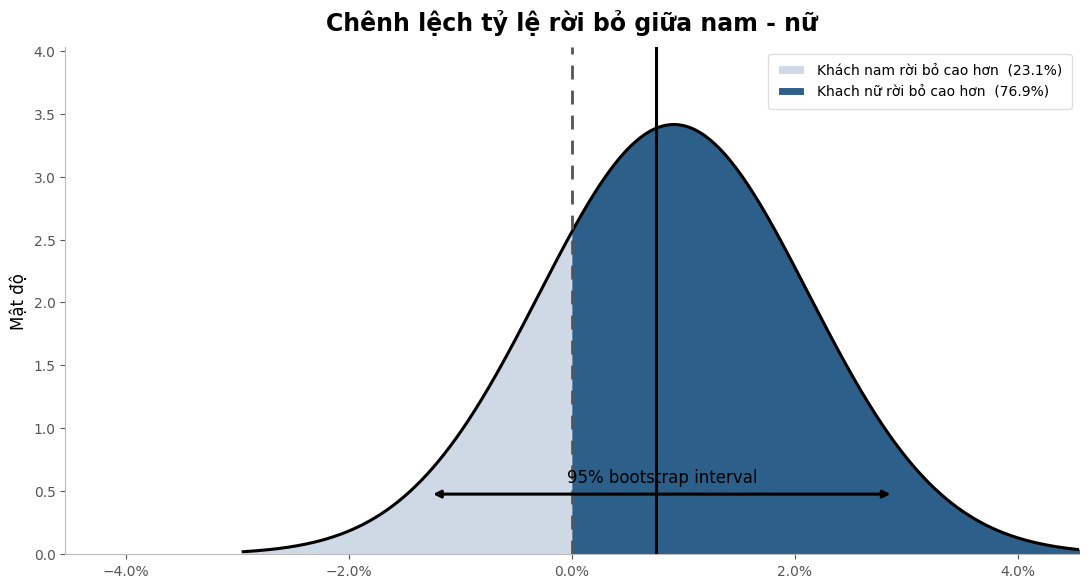

Female churn rate: 27.0%
Male churn rate: 26.2%
Chênh lệch Female − Male: +0.8%
95% bootstrap interval: [-1.3%, +2.9%]
Male churn cao hơn: 23.1%
Female churn cao hơn: 76.9%

Curve từ profile 10 dots: mu = 0.0092, sigma = 0.0121


In [ ]:
# =========================================================
# GENDER — DENSITY PLOT (dùng curve từ profile 10 dots)
# + Legend màu + đường 0% và mean nổi trên fill
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ----- 0. THAM SỐ -----
COL_GAP_10, ROW_GAP_10, DOT_SIZE_10, Y_START_10 = 0.0105, 0.88, 0.80, 0.60
CURVE_HEIGHT, CURVE_WIDTH, TAIL_SIGMA = 1.10, 1.15, 3.2

# ----- 1. DATA -----
female = df.loc[df["gender"] == "Female", "Churn_bin"].to_numpy()
male   = df.loc[df["gender"] == "Male",   "Churn_bin"].to_numpy()

# ----- 2. BOOTSTRAP -----
rng = np.random.default_rng(42); B = 5000; boot_diff = np.empty(B)
for i in range(B):
    sf = rng.choice(female, size=len(female), replace=True)
    sm = rng.choice(male,   size=len(male),   replace=True)
    boot_diff[i] = sf.mean() - sm.mean()

# ----- 3. SUMMARY -----
p_female, p_male = female.mean(), male.mean()
best_estimate = p_female - p_male
lo95, hi95 = np.quantile(boot_diff, [0.025, 0.975])
area_left  = np.mean(boot_diff < 0)
area_right = np.mean(boot_diff > 0)

# ----- 4. X LIMIT -----
q_lo, q_hi = np.quantile(boot_diff, [0.001, 0.999])
X_LIMIT = max(abs(q_lo), abs(q_hi), 0.04) + 0.005

# ----- 5. COLORS -----
MALE_C   = "#cfd9e6"   # xanh nhạt — Male
FEMALE_C = "#2c5f8a"   # xanh đậm  — Female

# ----- 6. GAP -> PIXEL/DATA -----
def get_equal_dy(ax, col_gap):
    ax.figure.canvas.draw()
    p0 = ax.transData.transform((0, 0)); px = ax.transData.transform((col_gap, 0))
    pixel_gap = abs(px[0] - p0[0]); py = p0 + np.array([0, pixel_gap])
    inv = ax.transData.inverted(); y0 = inv.transform(p0)[1]; y1 = inv.transform(py)[1]
    return abs(y1 - y0)

# ----- 7. PROFILE 10 DOTS -----
def build_profile_10(ax, col_gap, row_gap, dot_size_factor, y_start_factor):
    dy_equal = get_equal_dy(ax, col_gap); dy = dy_equal * row_gap
    dot_radius_y = dy_equal * dot_size_factor / 2
    y0 = dy_equal * y_start_factor
    cols = [
        (-0.0065, 2, MALE_C),
        ( 0.0065,               4, FEMALE_C),
        ( 0.0065 + col_gap,     3, FEMALE_C),
        ( 0.0065 + 2 * col_gap, 1, FEMALE_C),
    ]
    profile = []
    for cx, n, _ in cols:
        ys = y0 + np.arange(n) * dy
        profile.append({"x": cx, "count": n, "top": ys[-1] + dot_radius_y})
    return profile

# ----- 8. NORMAL CURVE TỪ PROFILE -----
def build_normal_curve(profile, col_gap, height_factor, width_factor, tail_sigma):
    xs      = np.array([p["x"]     for p in profile])
    weights = np.array([p["count"] for p in profile])
    tops    = np.array([p["top"]   for p in profile])
    mu = np.average(xs, weights=weights)
    sigma = np.sqrt(np.average((xs - mu) ** 2, weights=weights))
    sigma = max(sigma, col_gap) * width_factor
    curve_x = np.linspace(mu - tail_sigma * sigma, mu + tail_sigma * sigma, 600)
    curve_y = np.exp(-0.5 * ((curve_x - mu) / sigma) ** 2)
    curve_y *= tops.max() * height_factor
    return curve_x, curve_y, mu, sigma

# ----- 9. FIGURE -----
fig, ax = plt.subplots(figsize=(11, 6))

ax.set_xlim(-X_LIMIT, X_LIMIT)
ax.set_ylim(0, 4.0)
ax.xaxis.set_major_formatter(PercentFormatter(1))

profile = build_profile_10(ax, COL_GAP_10, ROW_GAP_10, DOT_SIZE_10, Y_START_10)
curve_x, curve_y, curve_mu, curve_sigma = build_normal_curve(
    profile, COL_GAP_10, CURVE_HEIGHT, CURVE_WIDTH, TAIL_SIGMA)

ax.set_ylim(0, curve_y.max() * 1.18)

# ----- VẼ DENSITY (fill zorder=2) -----
ax.plot(curve_x, curve_y, color="black", linewidth=2.2, zorder=3)
ax.fill_between(curve_x[curve_x <= 0], curve_y[curve_x <= 0],
                color=MALE_C,   alpha=1.0, zorder=2)
ax.fill_between(curve_x[curve_x >= 0], curve_y[curve_x >= 0],
                color=FEMALE_C, alpha=1.0, zorder=2)

# ----- MỐC 0 & BEST ESTIMATE (zorder cao để nổi trên fill) -----
ax.axvline(0, color="#555555", linestyle=(0, (5, 4)),
           linewidth=2.0, zorder=6)
ax.axvline(best_estimate, color="black",
           linewidth=2.2, zorder=6)

# ----- 95% CI ARROW -----
y_arrow = curve_y.max() * 0.14
ax.annotate("", xy=(hi95, y_arrow), xytext=(lo95, y_arrow),
            arrowprops=dict(arrowstyle="<|-|>", color="black", lw=2.2),
            zorder=7)
ax.text((lo95 + hi95) / 2, y_arrow * 1.12, "95% bootstrap interval",
        ha="center", va="bottom", fontsize=12, zorder=7)


# ----- LEGEND (chú thích màu + đường) -----
legend_handles = [
    Patch(facecolor=MALE_C,   edgecolor="white", linewidth=1.5,
          label=f"Khách nam rời bỏ cao hơn  ({area_left:.1%})"),
    Patch(facecolor=FEMALE_C, edgecolor="white", linewidth=1.5,
          label=f"Khach nữ rời bỏ cao hơn  ({area_right:.1%})")
]

ax.legend(handles=legend_handles, loc="upper right",
          frameon=True, fontsize=10,
          facecolor="white", edgecolor="#dddddd",
          framealpha=0.95, borderpad=0.7, labelspacing=0.55)

# ----- FORMAT -----
ax.set_title("Chênh lệch tỷ lệ rời bỏ giữa nam - nữ",
             fontsize=17, fontweight="bold", pad=12)
ax.set_ylabel("Mật độ", fontsize=12)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#bbbbbb"); ax.spines["bottom"].set_color("#bbbbbb")
ax.tick_params(axis="both", colors="#555555", labelsize=10)

plt.tight_layout(); plt.show()

# ----- OUTPUT -----
print(f"Female churn rate: {p_female:.1%}")
print(f"Male churn rate: {p_male:.1%}")
print(f"Chênh lệch Female − Male: {best_estimate:+.1%}")
print(f"95% bootstrap interval: [{lo95:+.1%}, {hi95:+.1%}]")
print(f"Male churn cao hơn: {area_left:.1%}")
print(f"Female churn cao hơn: {area_right:.1%}")
print(f"\nCurve từ profile 10 dots: mu = {curve_mu:.4f}, sigma = {curve_sigma:.4f}")

# Phần B — Bất định của point estimate

## Biểu đồ 4 — Raw sample + Mean ± SD / SE / CI (Figure 16.5)

**Có thể dùng trong Telco:** phân biệt:
- **SD**: khách hàng khác nhau bao nhiêu.
- **SE/CI**: ta biết trung bình của nhóm chính xác đến đâu.

**Ví dụ vẽ:** `MonthlyCharges` của khách hàng đã churn. Đây là một ví dụ tốt vì biến liên tục giúp thấy rõ SD và SE là hai khái niệm khác nhau.

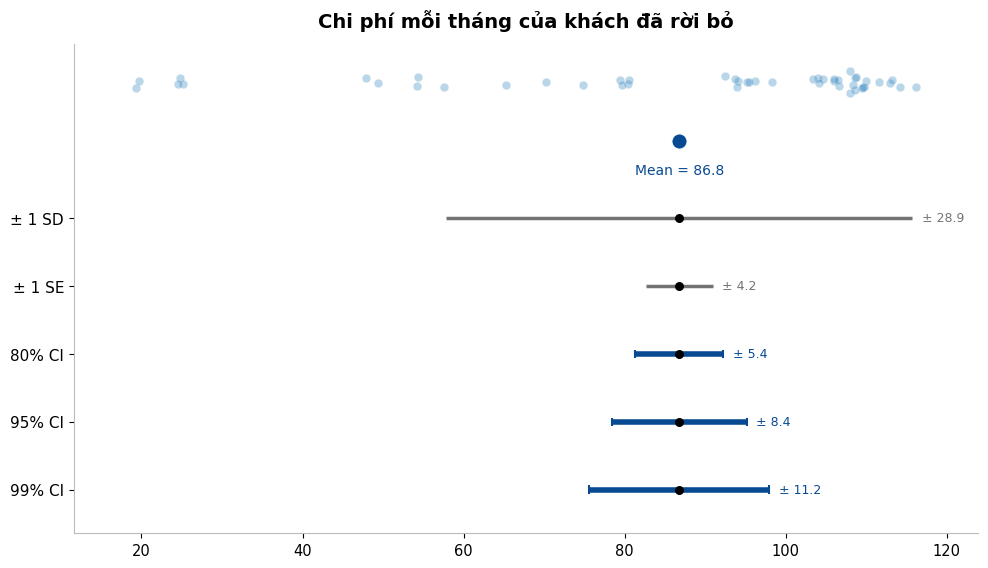

Số khách hàng trong nhóm: n = 48
Mean MonthlyCharges = 86.78
SD = 28.92
SE = 4.17

80% CI: [81.35, 92.20]
95% CI: [78.38, 95.17]
99% CI: [75.57, 97.98]

KẾT LUẬN:
MonthlyCharges của từng khách hàng phân tán khá rộng (SD ≈ 28.92), trong khi SE của trung bình chỉ ≈ 4.17.
Các khoảng 80%, 95% và 99% CI rộng dần khi mức độ tin cậy tăng. Nhờ chọn nhóm Contract = Two year, sự khác nhau giữa SD, SE và các mức CI dễ quan sát hơn.


In [ ]:
# =========================================================
# SD vs SE vs CI — khách churn + Contract = Two year
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# ----- 1. DATA -----
charges = df.loc[(df["Churn_bin"] == 1) & (df["Contract"] == "Two year"), "MonthlyCharges"].dropna().to_numpy()
n = len(charges); show = charges.copy()

# ----- 2. STATS -----
mean_c = charges.mean(); sd = charges.std(ddof=1); se = sd / np.sqrt(n)

# ----- 3. CI -----
levels = [0.80, 0.95, 0.99]
intervals = {lv: (mean_c - t.ppf(1-(1-lv)/2, df=n-1)*se,
                  mean_c + t.ppf(1-(1-lv)/2, df=n-1)*se) for lv in levels}

# ----- 4. FIGURE -----
fig, ax = plt.subplots(figsize=(10, 5.8))

# ----- 5. RAW DATA + MEAN -----
rng = np.random.default_rng(42)
ax.scatter(show, rng.normal(5.25, 0.055, size=len(show)), s=38, alpha=0.35,
           color=MID, edgecolor="white", linewidth=0.4, zorder=2)
ax.scatter(mean_c, 4.65, s=120, color=BLUE, edgecolor="white", linewidth=0.8, zorder=5)
ax.text(mean_c, 4.42, f"Mean = {mean_c:.1f}", ha="center", va="top", fontsize=10, color=BLUE)

# ----- 6. CÁC KHOẢNG -----
items = [("± 1 SD", mean_c-sd, mean_c+sd), ("± 1 SE", mean_c-se, mean_c+se),
         ("80% CI", *intervals[0.80]), ("95% CI", *intervals[0.95]), ("99% CI", *intervals[0.99])]
ROW_GAP, Y_FIRST = 0.70, 3.85
y_positions = [Y_FIRST - i*ROW_GAP for i in range(len(items))]

for (label, lo, hi), y_pos in zip(items, y_positions):
    is_ci = "CI" in label
    color = BLUE if is_ci else GRAY
    lw = 4 if is_ci else 2.5
    ax.hlines(y_pos, lo, hi, color=color, linewidth=lw, zorder=3)
    ax.scatter(mean_c, y_pos, s=30, color="black", zorder=5)
    if is_ci:
        ax.vlines([lo, hi], y_pos-0.045, y_pos+0.045, color=color, linewidth=1.5, zorder=4)
    ax.text(hi+1.2, y_pos, f"± {hi-mean_c:.1f}", va="center", fontsize=9, color=color)

# ----- 7. AXIS -----
ax.set_yticks(y_positions)
ax.set_yticklabels(["± 1 SD", "± 1 SE", "80% CI", "95% CI", "99% CI"], fontsize=11)
x_min = min(charges.min(), mean_c-sd); x_max = max(charges.max(), mean_c+sd)
pad = (x_max - x_min) * 0.08
ax.set_xlim(x_min-pad, x_max+pad); ax.set_ylim(0.6, 5.65)

# ----- 8. LABEL + STYLE -----
ax.set_title("Chi phí mỗi tháng của khách đã rời bỏ",
             fontsize=14, fontweight="bold", pad=12)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#bbbbbb"); ax.spines["bottom"].set_color("#bbbbbb")
ax.grid(False)

plt.tight_layout(); plt.show()

# ----- 9. OUTPUT -----
print(f"Số khách hàng trong nhóm: n = {n}")
print(f"Mean MonthlyCharges = {mean_c:.2f}")
print(f"SD = {sd:.2f}")
print(f"SE = {se:.2f}")
print()
for lv in levels:
    lo, hi = intervals[lv]
    print(f"{int(lv*100)}% CI: [{lo:.2f}, {hi:.2f}]")
print()
print("KẾT LUẬN:")
print(f"MonthlyCharges của từng khách hàng phân tán khá rộng (SD ≈ {sd:.2f}), "
      f"trong khi SE của trung bình chỉ ≈ {se:.2f}.")
print("Các khoảng 80%, 95% và 99% CI rộng dần khi mức độ tin cậy tăng. "
      "Nhờ chọn nhóm Contract = Two year, sự khác nhau giữa SD, SE "
      "và các mức CI dễ quan sát hơn.")

## Biểu đồ 5 — Graded error bars (Figures 16.6–16.7) ⭐ NÊN TRÌNH BÀY

**Có thể dùng trong Telco:**
- Churn rate theo `Contract`.
- Churn rate theo `PaymentMethod`.
- Churn rate theo `InternetService`.
- Churn rate theo `MultipleLines`

**Ví dụ vẽ:** 80%, 95%, 99% Wilson CI chồng lên nhau cho từng loại multiplelines.
"line" đơn giản là số kênh điện thoại khách đăng ký — càng nhiều line thường ám chỉ hộ gia đình đông người hoặc doanh nghiệp nhỏ.

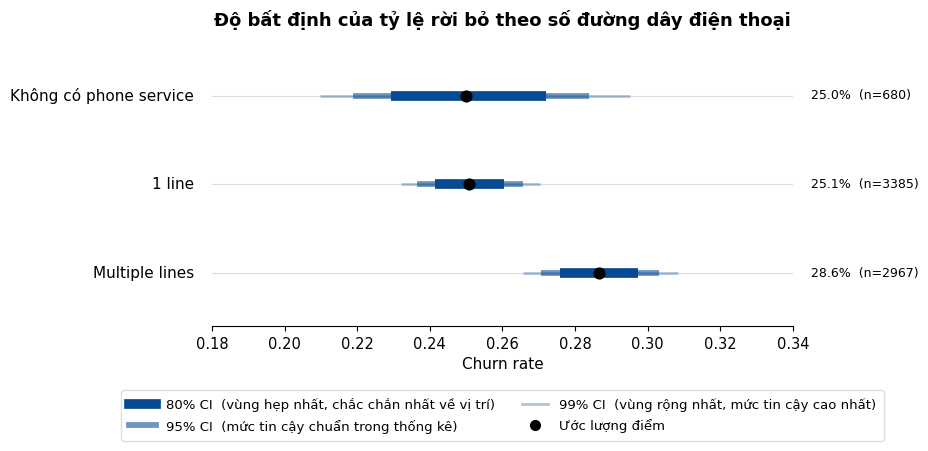

No phone service   | n =  680 | churn = 25.0%
No                 | n = 3385 | churn = 25.1%
Yes                | n = 2967 | churn = 28.6%

KẾT LUẬN: các nhóm có churn rate khá gần nhau, nhưng độ rộng CI khác nhau. Đặc biệt nhóm 'No phone service' có ít khách hàng hơn nên khoảng bất định rộng hơn.


In [ ]:
# =========================================================
# GRADED ERROR BARS — MULTIPLE LINES (forest-plot style)
# 80% / 95% / 99% Wilson CI, không dùng trục Oy
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from statsmodels.stats.proportion import proportion_confint

# ----- DATA -----
groups = ["No phone service", "No", "Yes"]
labels = ["Không có phone service", "1 line", "Multiple lines"]
styles = {0.99: (2.0, 0.32), 0.95: (4.2, 0.58), 0.80: (7.0, 1.00)}

fig, ax = plt.subplots(figsize=(9.5, 4.8))

# ----- VẼ TỪNG NHÓM TRÊN 1 HÀNG RIÊNG -----
summary = []
for y, (grp, lab) in enumerate(zip(groups, labels)):
    g = df[df["MultipleLines"] == grp]
    n, s = len(g), int(g["Churn_bin"].sum())
    p = s / n
    summary.append((grp, n, p))

    # Đường nền ngang cho nhóm này (thay cho trục Oy)
    ax.axhline(y, color="#dddddd", linewidth=0.8, zorder=1)

    # 3 lớp Wilson CI lồng nhau
    for lv in [0.99, 0.95, 0.80]:
        lo, hi = proportion_confint(s, n, alpha=1-lv, method="wilson")
        lw, alpha = styles[lv]
        ax.hlines(y, lo, hi, linewidth=lw, color=BLUE, alpha=alpha, zorder=3)

    # Điểm ước lượng
    ax.scatter(p, y, s=60, color="black", zorder=5)

    # Nhãn nhóm bên trái điểm estimate
    ax.text(0.175, y, lab, ha="right", va="center", fontsize=11)

    # Nhãn giá trị bên phải
    ax.text(0.345, y, f"{p:.1%}  (n={n})", ha="left", va="center", fontsize=9)

# ----- FORMAT -----
ax.set_ylim(-0.6, len(groups) - 0.4)
ax.set_xlim(0.18, 0.34)
ax.set_yticks([])
ax.set_xlabel("Churn rate", fontsize=11)
ax.set_title("Độ bất định của tỷ lệ rời bỏ theo số đường dây điện thoại",
             fontsize=13, fontweight="bold", pad=12)
ax.invert_yaxis()
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(False)

# ---------------------------------------------------------
# CHÚ THÍCH (legend) — 3 mức CI + điểm ước lượng
# ---------------------------------------------------------
legend_handles = [
    Line2D([0], [0], color=BLUE, linewidth=7.0, alpha=1.00,
           label="80% CI  (vùng hẹp nhất, chắc chắn nhất về vị trí)"),
    Line2D([0], [0], color=BLUE, linewidth=4.2, alpha=0.58,
           label="95% CI  (mức tin cậy chuẩn trong thống kê)"),
    Line2D([0], [0], color=BLUE, linewidth=2.0, alpha=0.32,
           label="99% CI  (vùng rộng nhất, mức tin cậy cao nhất)"),
    Line2D([0], [0], color="black", marker="o", linestyle="None",
           markersize=7, label="Ước lượng điểm"),
]

ax.legend(handles=legend_handles, loc="upper center",
          bbox_to_anchor=(0.5, -0.20), ncol=2,
          fontsize=9.5, frameon=True,
          facecolor="white", edgecolor="#dddddd",
          framealpha=0.95, borderpad=0.6, labelspacing=0.55)



plt.tight_layout(); plt.show()

# ----- OUTPUT -----
for grp, n, p in summary:
    print(f"{grp:18s} | n = {n:4d} | churn = {p:.1%}")
print()
print("KẾT LUẬN: các nhóm có churn rate khá gần nhau, nhưng độ rộng CI khác nhau. "
      "Đặc biệt nhóm 'No phone service' có ít khách hàng hơn nên khoảng bất định rộng hơn.")

## Biểu đồ 6 — CI cho **chênh lệch** giữa các nhóm (Figure 16.8) ⭐ NÊN TRÌNH BÀY

Wilke nhấn mạnh: không nên suy ra “khác biệt có ý nghĩa” chỉ bằng việc nhìn hai error bars có chồng lên nhau hay không.

Có thể dùng trong Telco: tính trực tiếp churn(group) − churn(Credit card automatic).

Ví dụ vẽ: Bank transfer, Mailed check, Electronic check so với Credit card automatic bằng bootstrap difference — graded error bars 80% / 95% / 99% CI lồng nhau.

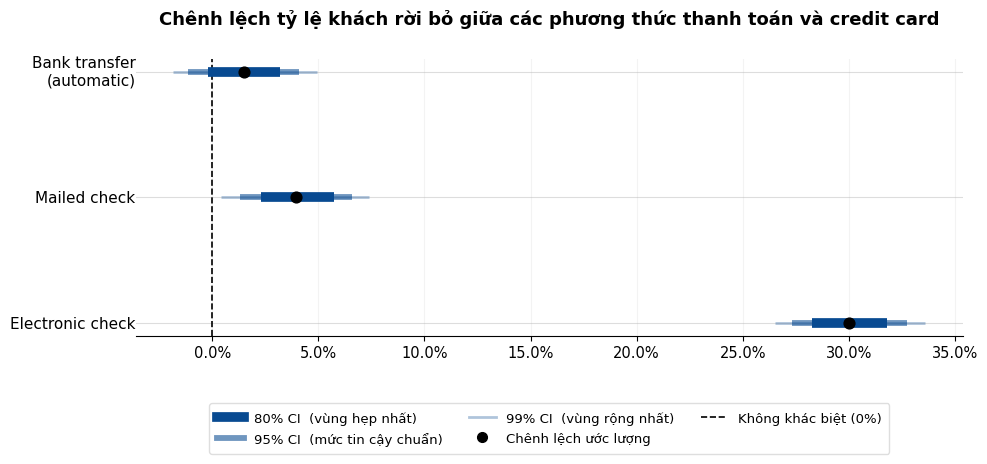

Nhóm chuẩn: Credit card (automatic)
Churn rate = 15.3%, n = 1521

Bank transfer (automatic):
  churn = 16.7%, n = 1542
  chênh lệch = +1.5%
  95% CI = [-1.1%, +4.1%]  → CI chứa 0

Mailed check:
  churn = 19.2%, n = 1604
  chênh lệch = +3.9%
  95% CI = [+1.3%, +6.6%]  → CI không chứa 0

Electronic check:
  churn = 45.3%, n = 2365
  chênh lệch = +30.0%
  95% CI = [+27.3%, +32.8%]  → CI không chứa 0

KẾT LUẬN: Bank transfer có chênh lệch nhỏ và CI vẫn cắt qua 0; Mailed check có chênh lệch vừa phải; Electronic check có churn cao hơn Credit card rất rõ. Biểu đồ cho thấy tại sao nên xem trực tiếp CI của chênh lệch, thay vì chỉ so sánh hai point estimate hoặc hai error bar riêng.


In [ ]:
# =========================================================
# GRADED ERROR BARS — DIFFERENCE IN CHURN RATE BY PAYMENT METHOD
# Base = Credit card (automatic)
# 80% / 95% / 99% bootstrap CI lồng nhau
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D

# ----- 1. BASE GROUP -----
base_name = "Credit card (automatic)"
base = df.loc[df["PaymentMethod"] == base_name, "Churn_bin"].to_numpy()
base_p, n0 = base.mean(), len(base)

# ----- 2. GROUPS TO COMPARE -----
compare_groups = ["Bank transfer (automatic)", "Mailed check", "Electronic check"]

# ----- 3. BOOTSTRAP DIFFERENCE -----
B = 6000
levels = [0.99, 0.95, 0.80]
styles = {0.99: (2.0, 0.32), 0.95: (4.2, 0.58), 0.80: (7.0, 1.00)}

rows = []
for i, group_name in enumerate(compare_groups):
    vals = df.loc[df["PaymentMethod"] == group_name, "Churn_bin"].to_numpy()
    p, n = vals.mean(), len(vals)

    rng = np.random.default_rng(42 + i)
    boot_diff = (rng.binomial(n, p, B) / n) - (rng.binomial(n0, base_p, B) / n0)

    diff = p - base_p
    ci = {lv: np.quantile(boot_diff, [(1-lv)/2, 1-(1-lv)/2]) for lv in levels}
    rows.append((group_name, p, n, diff, ci))

# ----- 4. FIGURE -----
fig, ax = plt.subplots(figsize=(10, 5))

for y, (group_name, p, n, diff, ci) in enumerate(rows):
    # Đường nền
    ax.axhline(y, color="#dddddd", linewidth=0.8, zorder=1)

    # 3 lớp CI lồng nhau
    for lv in levels:
        lo, hi = ci[lv]
        lw, alpha = styles[lv]
        ax.hlines(y, lo, hi, linewidth=lw, color=BLUE, alpha=alpha, zorder=3)

    # Điểm ước lượng
    ax.scatter(diff, y, s=60, color="black", zorder=5)



# ----- 5. ZERO LINE -----
ax.axvline(0, color="black", linestyle="--", linewidth=1.2, zorder=2)


# ----- 6. LABELS -----
labels = ["Bank transfer\n(automatic)", "Mailed check", "Electronic check"]
ax.set_yticks([])
ax.invert_yaxis()
ax.set_title("Chênh lệch tỷ lệ khách rời bỏ giữa các phương thức thanh toán và credit card",
             fontsize=13, fontweight="bold", pad=25)

# ----- 7. FORMAT -----
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", alpha=0.15)

# Nhãn nhóm đặt bên trái khung (thay cho trục Oy)
x_left = ax.get_xlim()[0]
for y, lab in enumerate(labels):
    ax.text(x_left, y, lab, ha="right", va="center", fontsize=11)

# ---------------------------------------------------------
# CHÚ THÍCH (legend) — 3 mức CI + điểm ước lượng + đường 0
# ---------------------------------------------------------
legend_handles = [
    Line2D([0], [0], color=BLUE, linewidth=7.0, alpha=1.00,
           label="80% CI  (vùng hẹp nhất)"),
    Line2D([0], [0], color=BLUE, linewidth=4.2, alpha=0.58,
           label="95% CI  (mức tin cậy chuẩn)"),
    Line2D([0], [0], color=BLUE, linewidth=2.0, alpha=0.32,
           label="99% CI  (vùng rộng nhất)"),
    Line2D([0], [0], color="black", marker="o", linestyle="None",
           markersize=7, label="Chênh lệch ước lượng"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=1.2,
           label="Không khác biệt (0%)"),
]

ax.legend(handles=legend_handles, loc="upper center",
          bbox_to_anchor=(0.5, -0.22), ncol=3,
          fontsize=9.5, frameon=True,
          facecolor="white", edgecolor="#dddddd",
          framealpha=0.95, borderpad=0.6, labelspacing=0.55)




plt.tight_layout(); plt.show()

# ----- 8. OUTPUT -----
print(f"Nhóm chuẩn: {base_name}")
print(f"Churn rate = {base_p:.1%}, n = {n0}")
print()
for group_name, p, n, diff, ci in rows:
    lo95, hi95 = ci[0.95]
    note = "CI chứa 0" if lo95 <= 0 <= hi95 else "CI không chứa 0"
    print(f"{group_name}:")
    print(f"  churn = {p:.1%}, n = {n}")
    print(f"  chênh lệch = {diff:+.1%}")
    print(f"  95% CI = [{lo95:+.1%}, {hi95:+.1%}]  → {note}")
    print()
print("KẾT LUẬN: Bank transfer có chênh lệch nhỏ và CI vẫn cắt qua 0; "
      "Mailed check có chênh lệch vừa phải; Electronic check có churn "
      "cao hơn Credit card rất rõ. Biểu đồ cho thấy tại sao nên xem trực "
      "tiếp CI của chênh lệch, thay vì chỉ so sánh hai point estimate "
      "hoặc hai error bar riêng.")

## Biểu đồ 9 — Các cách vẽ cùng một bất định: cap / no-cap / confidence strip / confidence distribution (Figure 16.9)

**Có thể dùng trong Telco:** khi muốn chọn kiểu hiển thị phù hợp với người nghe.

**Ví dụ vẽ:** cùng một bootstrap distribution của từng loại multiplelines bằng nhiều cách.

Trục X chung: 19.2% → 32.2%


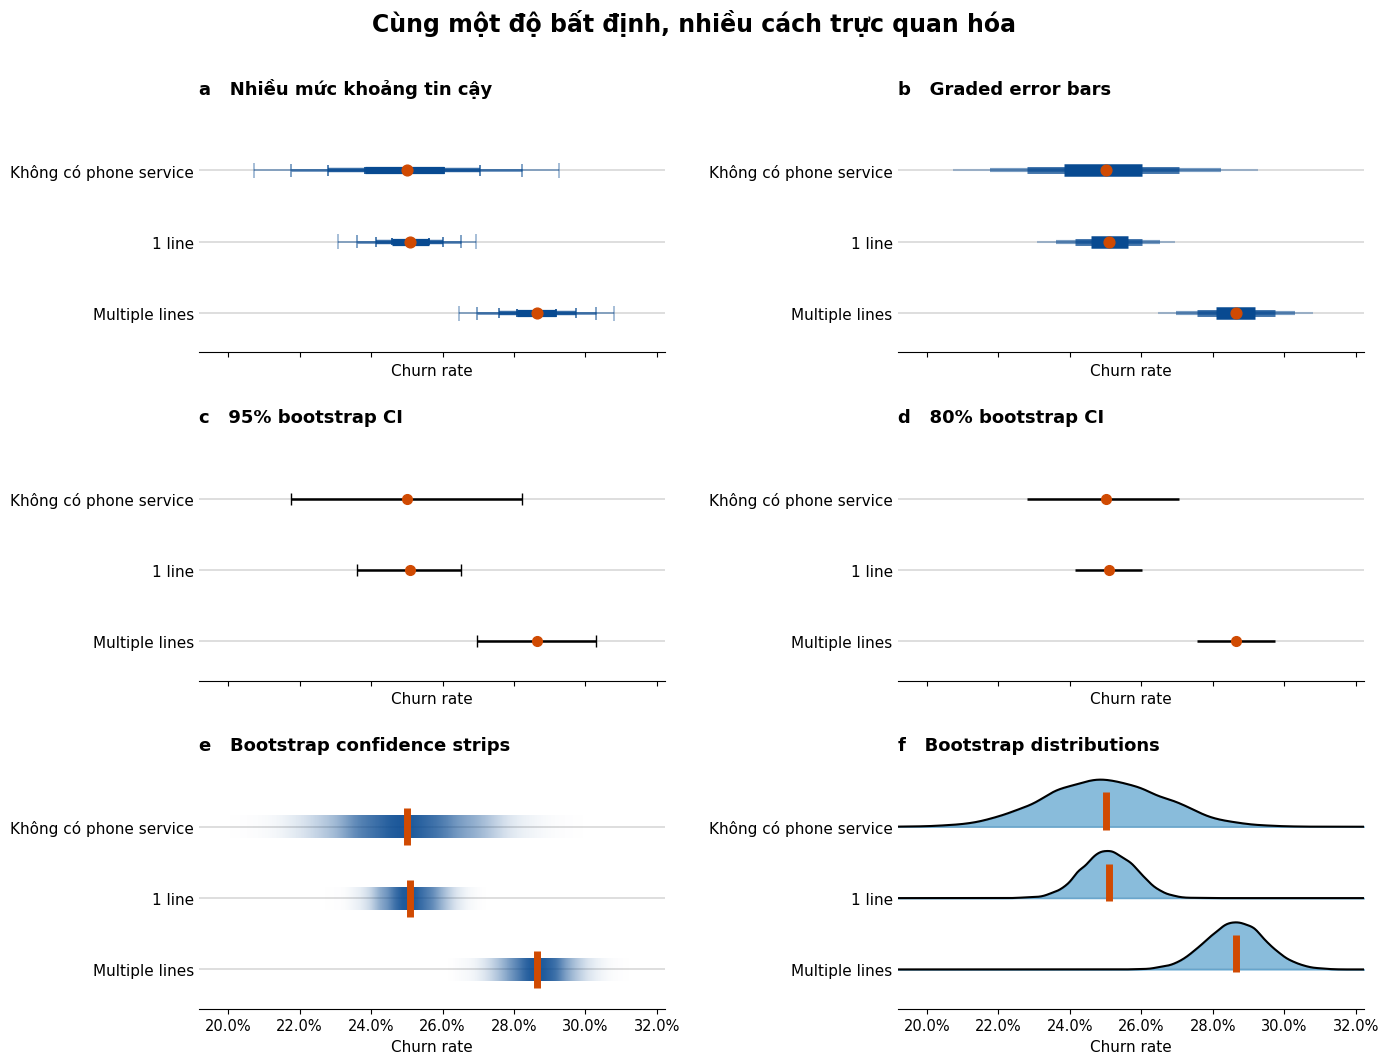

Tất cả 6 panel đều biểu diễn churn rate của từng nhóm MultipleLines.

Không có phone service | n= 680 | p=25.0%
   80% CI [22.8%, 27.1%]
   95% CI [21.8%, 28.2%]
   99% CI [20.7%, 29.3%]

1 line                 | n=3385 | p=25.1%
   80% CI [24.1%, 26.0%]
   95% CI [23.6%, 26.5%]
   99% CI [23.1%, 26.9%]

Multiple lines         | n=2967 | p=28.6%
   80% CI [27.6%, 29.7%]
   95% CI [27.0%, 30.3%]
   99% CI [26.5%, 30.8%]

KẾT LUẬN: Ba nhóm có churn rate khoảng 25%–29%. Điểm ước lượng không thay đổi giữa các panel; chỉ cách thể hiện uncertainty thay đổi. Panel a–d tóm tắt bootstrap distribution bằng các khoảng; panel e mã hóa toàn bộ distribution bằng độ đậm; panel f trực tiếp cho thấy hình dạng của distribution.


In [ ]:
# =========================================================
# NHIỀU CÁCH TRỰC QUAN HÓA CÙNG MỘT UNCERTAINTY
# churn rate của từng nhóm MultipleLines — cùng 1 bootstrap dist
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import to_rgb

# ----- 0. CONFIG -----
B, SEED = 8000, 42
groups = ["No phone service", "No", "Yes"]
labels = ["Không có phone service", "1 line", "Multiple lines"]
BLUE = plt.cm.Blues(0.90); MID = plt.cm.Blues(0.60)
POINT_COLOR = "#D04A02"; GRID_COLOR = "#D4D4D4"
LEVELS = [0.99, 0.95, 0.80, 0.50]

# ----- 1. BOOTSTRAP -----
results = []
for i, gname in enumerate(groups):
    vals = df.loc[df["MultipleLines"] == gname, "Churn_bin"].dropna().to_numpy()
    n, s, p = len(vals), int(vals.sum()), vals.mean()
    rng = np.random.default_rng(SEED + i)
    boot = rng.binomial(n, p, B) / n
    intervals = {lv: tuple(np.quantile(boot, [(1-lv)/2, 1-(1-lv)/2])) for lv in LEVELS}
    results.append({"label": labels[i], "n": n, "p": p, "boot": boot, "intervals": intervals})

# ----- 2. COMMON X RANGE -----
all_boot = np.concatenate([r["boot"] for r in results])
lo_q, hi_q = np.quantile(all_boot, [0.001, 0.999])
pad = (hi_q - lo_q) * 0.12
XMIN, XMAX = lo_q - pad, hi_q + pad
print(f"Trục X chung: {XMIN:.1%} → {XMAX:.1%}")

# ----- 3. BASE PANEL -----
def base_panel(ax):
    for y in range(len(results)):
        ax.axhline(y, color=GRID_COLOR, linewidth=1.1, zorder=0)
    ax.set_xlim(XMIN, XMAX); ax.set_ylim(-0.95, len(results) - 0.45)
    ax.set_yticks(range(len(results))); ax.set_yticklabels(labels, fontsize=11)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel("Churn rate", fontsize=11)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)

# ----- 4. FIGURE -----
fig, axes = plt.subplots(3, 2, figsize=(14, 10.5), sharex=True)
axes = axes.flatten()

# ----- A. NHIỀU MỨC KHOẢNG TIN CẬY -----
ax = axes[0]; base_panel(ax)
styles_a = {0.99: (1.4, 0.105, 0.42), 0.95: (2.0, 0.090, 0.60),
            0.80: (3.2, 0.072, 0.80), 0.50: (5.2, 0.052, 1.00)}
for i, r in enumerate(results):
    for lv in LEVELS:
        lo, hi = r["intervals"][lv]; lw, cap, alpha = styles_a[lv]
        ax.hlines(i, lo, hi, color=BLUE, linewidth=lw, alpha=alpha, zorder=2)
        ax.vlines([lo, hi], i-cap, i+cap, color=BLUE, linewidth=1.2, alpha=alpha, zorder=2)
    ax.scatter(r["p"], i, s=60, color=POINT_COLOR, zorder=5)
ax.set_title("a   Nhiều mức khoảng tin cậy", loc="left", fontsize=13, fontweight="bold")

# ----- B. GRADED ERROR BARS -----
ax = axes[1]; base_panel(ax)
styles_b = {0.99: (1.5, 0.32), 0.95: (3.0, 0.52), 0.80: (5.0, 0.75), 0.50: (9.0, 1.00)}
for i, r in enumerate(results):
    for lv in LEVELS:
        lo, hi = r["intervals"][lv]; lw, alpha = styles_b[lv]
        ax.hlines(i, lo, hi, color=BLUE, linewidth=lw, alpha=alpha, zorder=2)
    ax.scatter(r["p"], i, s=60, color=POINT_COLOR, zorder=5)
ax.set_title("b   Graded error bars", loc="left", fontsize=13, fontweight="bold")

# ----- C. 95% CI -----
ax = axes[2]; base_panel(ax)
for i, r in enumerate(results):
    lo, hi = r["intervals"][0.95]
    ax.errorbar(r["p"], i, xerr=[[r["p"]-lo], [hi-r["p"]]],
                fmt="o", color="black", markerfacecolor=POINT_COLOR,
                markeredgecolor=POINT_COLOR, markersize=7,
                capsize=4, linewidth=1.8, zorder=3)
ax.set_title("c   95% bootstrap CI", loc="left", fontsize=13, fontweight="bold")

# ----- D. 80% CI -----
ax = axes[3]; base_panel(ax)
for i, r in enumerate(results):
    lo, hi = r["intervals"][0.80]
    ax.errorbar(r["p"], i, xerr=[[r["p"]-lo], [hi-r["p"]]],
                fmt="o", color="black", markerfacecolor=POINT_COLOR,
                markeredgecolor=POINT_COLOR, markersize=7,
                capsize=0, linewidth=1.8, zorder=3)
ax.set_title("d   80% bootstrap CI", loc="left", fontsize=13, fontweight="bold")

# ----- E. CONFIDENCE STRIP -----
x_grid = np.linspace(XMIN, XMAX, 700)
rgb = np.array(to_rgb(BLUE))
ax = axes[4]; base_panel(ax)
for i, r in enumerate(results):
    density = gaussian_kde(r["boot"])(x_grid)
    density /= density.max()
    alpha = density**1.25 * 0.92
    rgba = np.zeros((1, len(x_grid), 4))
    rgba[0, :, :3] = rgb; rgba[0, :, 3] = alpha
    ax.imshow(rgba, extent=[XMIN, XMAX, i-0.16, i+0.16],
              aspect="auto", interpolation="bicubic", zorder=2)
    ax.vlines(r["p"], i-0.26, i+0.26, color=POINT_COLOR, linewidth=5, zorder=5)
ax.set_title("e   Bootstrap confidence strips", loc="left", fontsize=13, fontweight="bold")

# ----- F. FULL DISTRIBUTION -----
ax = axes[5]; base_panel(ax)
RIDGE_HEIGHT = 0.66
for i, r in enumerate(results):
    density = gaussian_kde(r["boot"])(x_grid)
    density = density / density.max() * RIDGE_HEIGHT
    ridge_y = i - density
    ax.fill_between(x_grid, i, ridge_y, color=MID, alpha=0.65, zorder=2)
    ax.plot(x_grid, ridge_y, color="black", linewidth=1.5, zorder=3)
    ax.vlines(r["p"], i-0.48, i+0.04, color=POINT_COLOR, linewidth=5, zorder=5)
ax.set_title("f   Bootstrap distributions", loc="left", fontsize=13, fontweight="bold")

# ----- TITLE -----
fig.suptitle("Cùng một độ bất định, nhiều cách trực quan hóa",
             fontsize=17, fontweight="bold", y=1.01)
plt.tight_layout(h_pad=2.1, w_pad=2.0); plt.show()

# ----- SUMMARY -----
print("Tất cả 6 panel đều biểu diễn churn rate của từng nhóm MultipleLines.\n")
for r in results:
    lo80, hi80 = r["intervals"][0.80]
    lo95, hi95 = r["intervals"][0.95]
    lo99, hi99 = r["intervals"][0.99]
    print(f"{r['label']:22s} | n={r['n']:4d} | p={r['p']:.1%}")
    print(f"   80% CI [{lo80:.1%}, {hi80:.1%}]")
    print(f"   95% CI [{lo95:.1%}, {hi95:.1%}]")
    print(f"   99% CI [{lo99:.1%}, {hi99:.1%}]\n")
print("KẾT LUẬN: Ba nhóm có churn rate khoảng 25%–29%. Điểm ước lượng không "
      "thay đổi giữa các panel; chỉ cách thể hiện uncertainty thay đổi. "
      "Panel a–d tóm tắt bootstrap distribution bằng các khoảng; panel e "
      "mã hóa toàn bộ distribution bằng độ đậm; panel f trực tiếp cho thấy "
      "hình dạng của distribution.")

## Biểu đồ 10 — Bar chart + error bars (Figure 16.10)

**Có thể dùng trong Telco:** báo cáo quản trị quen thuộc, khi người xem thích bar chart.

**Ví dụ vẽ:** churn theo Contract, bar = point estimate, error = 95% CI.

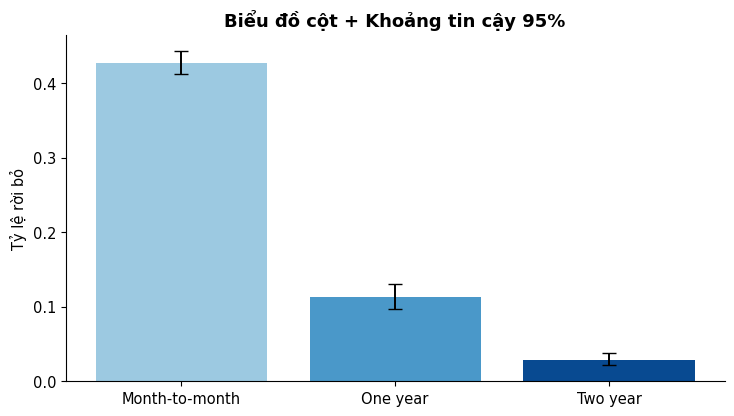

KẾT LUẬN: hình dạng bar không thay thế thông tin bất định; luôn ghi rõ đây là 95% Wilson CI.


In [ ]:
contracts = ['Month-to-month', 'One year', 'Two year']
ct = rate_summary(df, 'Contract', .95).set_index('Contract').loc[contracts].reset_index()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x = np.arange(len(ct))
ax.bar(x, ct['rate'], color=[LIGHT, MID, BLUE])
ax.errorbar(x, ct['rate'], yerr=[ct['rate']-ct['lo'], ct['hi']-ct['rate']],
            fmt='none', ecolor='black', capsize=5, lw=1.4)
ax.set_xticks(x); ax.set_xticklabels(ct['Contract'])
ax.set_ylabel('Tỷ lệ rời bỏ')
ax.set_title('Biểu đồ cột + Khoảng tin cậy 95%')
plt.show()

print("KẾT LUẬN: hình dạng bar không thay thế thông tin bất định; luôn ghi rõ đây là 95% Wilson CI.")

## Biểu đồ 13 — Frequentist CI vs Bayesian credible interval (Figure 16.13)

**Có thể dùng trong Telco:** so hai cách diễn đạt bất định của churn rate theo Contract, phương thức thanh toán

Bayesian demo dùng prior đơn giản `Beta(1,1)`; đây là minh họa trực quan, không phải mô hình Bayesian phức tạp.

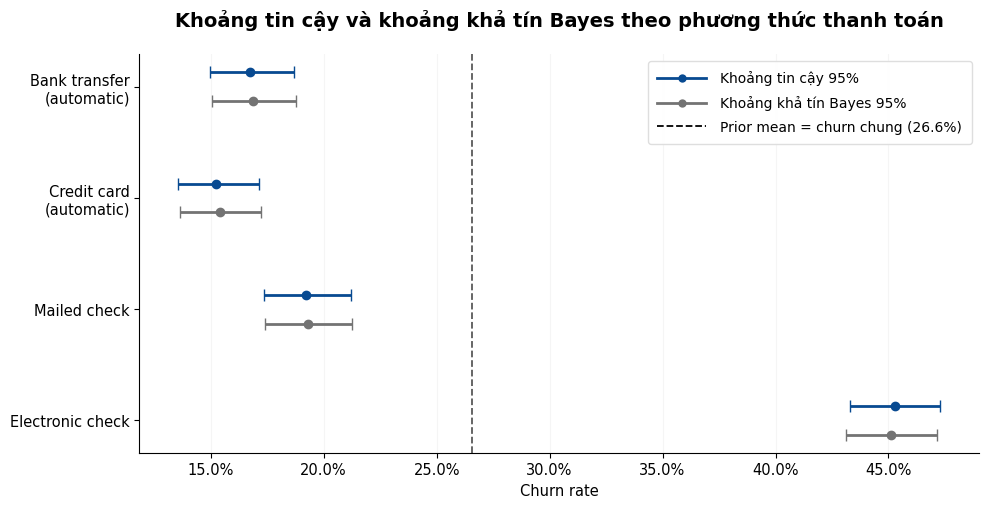

Prior knowledge: churn rate chung = 26.6%
Prior strength = 20

Bank transfer (automatic)
  n = 1542
  Frequentist: 16.7%, 95% CI [15.0%, 18.7%]
  Bayesian:    16.9%, 95% CrI [15.0%, 18.8%]

Credit card (automatic)
  n = 1521
  Frequentist: 15.3%, 95% CI [13.5%, 17.1%]
  Bayesian:    15.4%, 95% CrI [13.6%, 17.2%]

Mailed check
  n = 1604
  Frequentist: 19.2%, 95% CI [17.3%, 21.2%]
  Bayesian:    19.3%, 95% CrI [17.4%, 21.2%]

Electronic check
  n = 2365
  Frequentist: 45.3%, 95% CI [43.3%, 47.3%]
  Bayesian:    45.1%, 95% CrI [43.1%, 47.1%]

KẾT LUẬN: Bayesian bắt đầu từ prior là churn rate chung của toàn bộ khách hàng. Sau khi quan sát dữ liệu của từng PaymentMethod, posterior được cập nhật. Do các nhóm có cỡ mẫu khá lớn, dữ liệu chiếm ưu thế nên Bayesian CrI và Frequentist CI thường khá gần nhau.


In [ ]:
# =========================================================
# FREQUENTIST CI vs BAYESIAN CrI — PAYMENT METHOD
# Prior: churn rate chung của toàn bộ khách hàng
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta, norm
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D

# ----- 1. PAYMENT METHODS -----
payment_methods = ["Bank transfer (automatic)", "Credit card (automatic)",
                   "Mailed check", "Electronic check"]

# ----- 2. PRIOR -----
overall_p = df["Churn_bin"].mean()
PRIOR_STRENGTH = 20
prior_alpha = overall_p * PRIOR_STRENGTH
prior_beta  = (1 - overall_p) * PRIOR_STRENGTH

# ----- 3. WILSON CI -----
def wilson_ci(s, n, conf=0.95):
    p = s / n; z = norm.ppf(1 - (1 - conf) / 2)
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    margin = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denom
    return center - margin, center + margin

# ----- 4. TÍNH FREQUENTIST + BAYESIAN -----
rows = []
for method in payment_methods:
    g = df[df["PaymentMethod"] == method]
    n, s = len(g), int(g["Churn_bin"].sum())
    p = s / n
    flo, fhi = wilson_ci(s, n, 0.95)

    post_a = prior_alpha + s
    post_b = prior_beta + n - s
    post_mean = post_a / (post_a + post_b)
    blo, bhi = beta.ppf([0.025, 0.975], post_a, post_b)

    rows.append((method, n, p, flo, fhi, post_mean, blo, bhi))

# ----- 5. FIGURE -----
fig, ax = plt.subplots(figsize=(10, 5.2))

for i, (method, n, p, flo, fhi, post_mean, blo, bhi) in enumerate(rows):
    ax.errorbar(p, i - 0.13, xerr=[[p-flo], [fhi-p]],
                fmt="o", markersize=6, capsize=4, linewidth=2,
                color=BLUE, zorder=4)
    ax.errorbar(post_mean, i + 0.13, xerr=[[post_mean-blo], [bhi-post_mean]],
                fmt="o", markersize=6, capsize=4, linewidth=2,
                color=GRAY, zorder=4)

# ----- 6. PRIOR MEAN -----
ax.axvline(overall_p, color="black", linestyle="--", linewidth=1.3, alpha=0.65)

# ----- 7. LABELS -----
labels = ["Bank transfer\n(automatic)", "Credit card\n(automatic)",
          "Mailed check", "Electronic check"]
ax.set_yticks(range(len(rows)))
ax.set_yticklabels(labels)
ax.invert_yaxis()

# ----- 8. FORMAT -----
ax.set_xlabel("Churn rate")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Khoảng tin cậy và khoảng khả tín Bayes theo phương thức thanh toán",
             fontsize=14, fontweight="bold", pad = 20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.12)

# ----- 9. LEGEND Ở GÓC TRÊN PHẢI -----
legend_handles = [
    Line2D([0], [0], color=BLUE, marker="o", markersize=6,
           linewidth=2, markeredgewidth=0,
           label="Khoảng tin cậy 95%"),
    Line2D([0], [0], color=GRAY, marker="o", markersize=6,
           linewidth=2, markeredgewidth=0,
           label="Khoảng khả tín Bayes 95%"),
    Line2D([0], [0], color="black", linestyle="--", linewidth=1.3,
           label=f"Prior mean = churn chung ({overall_p:.1%})"),
]

ax.legend(handles=legend_handles, loc="upper right",
          frameon=True, facecolor="white", edgecolor="#dddddd",
          framealpha=0.95, fontsize=10, borderpad=0.7,
          labelspacing=0.7, handlelength=3.5, handletextpad=1.0)

plt.tight_layout(); plt.show()

# ----- 10. OUTPUT -----
print(f"Prior knowledge: churn rate chung = {overall_p:.1%}")
print(f"Prior strength = {PRIOR_STRENGTH}")
print()
for method, n, p, flo, fhi, post_mean, blo, bhi in rows:
    print(method)
    print(f"  n = {n}")
    print(f"  Frequentist: {p:.1%}, 95% CI [{flo:.1%}, {fhi:.1%}]")
    print(f"  Bayesian:    {post_mean:.1%}, 95% CrI [{blo:.1%}, {bhi:.1%}]")
    print()
print("KẾT LUẬN: Bayesian bắt đầu từ prior là churn rate chung của toàn bộ "
      "khách hàng. Sau khi quan sát dữ liệu của từng PaymentMethod, posterior "
      "được cập nhật. Do các nhóm có cỡ mẫu khá lớn, dữ liệu chiếm ưu thế "
      "nên Bayesian CrI và Frequentist CI thường khá gần nhau.")

# Phần C — Bất định của đường xu hướng

## Chuẩn bị: churn theo các khoảng tenure

Ta gom tenure thành các khoảng để tỷ lệ churn ổn định hơn, sau đó minh họa uncertainty của đường fit.

In [ ]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = ['1–6','7–12','13–24','25–36','37–48','49–60','61–72']
df['tenure_bin'] = pd.cut(df['tenure'], bins=bins, labels=labels, include_lowest=True)

tb = (df.groupby('tenure_bin', observed=True)
        .agg(n=('Churn_bin','size'), churned=('Churn_bin','sum'), rate=('Churn_bin','mean'), tenure_mean=('tenure','mean'))
        .reset_index())
tb

,tenure_bin,n,churned,rate,tenure_mean
0,1–6,1470,784,0.533333,2.529252
1,7–12,705,253,0.358865,9.397163
2,13–24,1024,294,0.287109,18.351562
3,25–36,832,180,0.216346,30.338942
4,37–48,762,145,0.190289,42.581365
5,49–60,832,120,0.144231,54.489183
6,61–72,1407,93,0.066098,68.110163


In [ ]:
def bootstrap_poly_curves(summary, degree=1, B=1500, seed=42, grid=None):
    rng = np.random.default_rng(seed)
    x = summary['tenure_mean'].to_numpy(float)
    n = summary['n'].to_numpy(int)
    p = summary['rate'].to_numpy(float)
    if grid is None:
        grid = np.linspace(x.min(), x.max(), 220)
    curves = np.empty((B, len(grid)))
    for b in range(B):
        yb = rng.binomial(n, p)/n
        coef = np.polyfit(x, yb, degree)
        curves[b] = np.polyval(coef, grid)
    return grid, curves

## Biểu đồ 15 — Confidence band của đường fit (Figure 16.15)

**Có thể dùng trong Telco:** churn thay đổi theo tenure như thế nào, và xu hướng đó chắc chắn đến đâu?

**Ví dụ vẽ:** linear trend trên churn rate theo tenure bin + 95% bootstrap band.

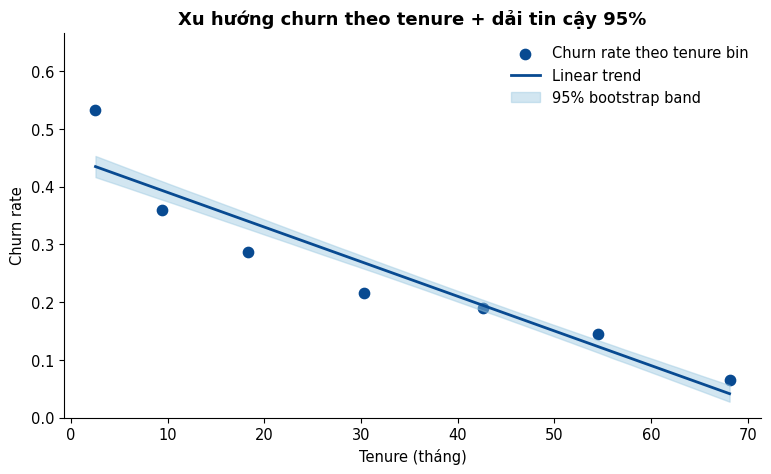


 Đường thẳng màu xanh biểu thị đường khớp tuyến tính tốt nhất với dữ liệu, còn dải xanh nhạt bao quanh 
 thể hiện sự bất định của đường khớp tuyến tính tương ứng với mức tin cậy 95%

 KẾT LUẬN: slope ước lượng = -0.0060 churn-rate/tháng.
Trong dataset này churn có xu hướng giảm khi tenure tăng; band cho thấy mức bất định của toàn đường xu hướng.


In [ ]:
x = tb['tenure_mean'].to_numpy(float)
y = tb['rate'].to_numpy(float)
grid, curves_lin = bootstrap_poly_curves(tb, degree=1, B=2000, seed=10)
coef = np.polyfit(x,y,1)
best = np.polyval(coef,grid)
lo, hi = np.quantile(curves_lin, [.025,.975], axis=0)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x,y,s=55,color=BLUE,label='Churn rate theo tenure bin')
ax.plot(grid,best,color=BLUE,lw=2,label='Linear trend')
ax.fill_between(grid,lo,hi,color=LIGHT,alpha=.45,label='95% bootstrap band')
ax.set_xlabel('Tenure (tháng)')
ax.set_ylabel('Churn rate')
ax.set_ylim(0, min(1, max(y)*1.25))
ax.set_title('Xu hướng churn theo tenure + dải tin cậy 95%')
ax.legend(frameon=False)
plt.show()
print(f"\n Đường thẳng màu xanh biểu thị đường khớp tuyến tính tốt nhất với dữ liệu, còn dải xanh nhạt bao quanh \n thể hiện sự bất định của đường khớp tuyến tính tương ứng với mức tin cậy 95%")
print(f"\n KẾT LUẬN: slope ước lượng = {coef[0]:+.4f} churn-rate/tháng.")
print("Trong dataset này churn có xu hướng giảm khi tenure tăng; band cho thấy mức bất định của toàn đường xu hướng.")

## Biểu đồ 16 — Alternative fitted lines (Figure 16.16)

**Có thể dùng trong Telco:** cho người xem thấy confidence band thực chất đại diện cho nhiều đường fit hợp lý khác nhau.

**Ví dụ vẽ:** 15 linear fits lấy từ bootstrap.

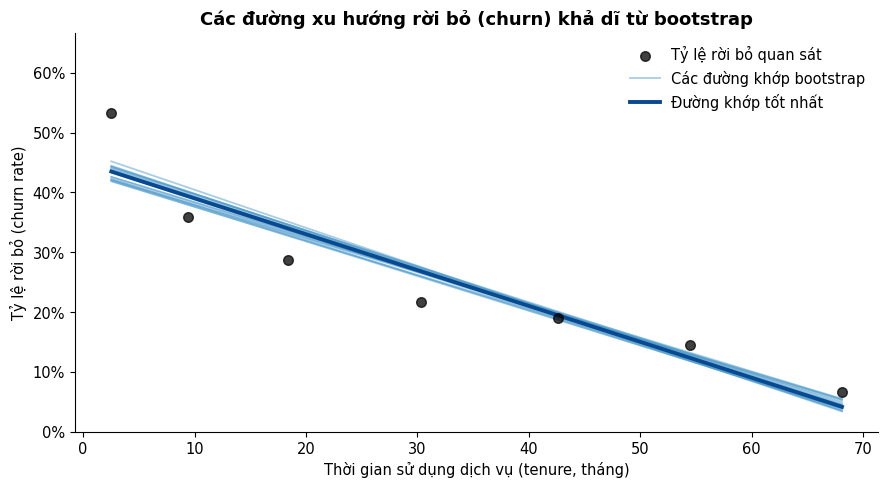


 KẾT LUẬN: Sự bất định không chỉ được biểu diễn bằng một dải màu. Nó còn có thể được thể hiện 
 bằng nhiều đường xu hướng được sinh ra từ quá trình bootstrap.


In [ ]:
from matplotlib.ticker import PercentFormatter

rng_lines = np.random.default_rng(16)

sample_idx = rng_lines.choice(
    len(curves_lin),
    size=15,
    replace=False
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    x, y,
    s=48,
    color='black',
    alpha=0.75,
    label='Tỷ lệ rời bỏ quan sát',
    zorder=4
)

for i, curve in enumerate(curves_lin[sample_idx]):
    ax.plot(
        grid,
        curve,
        color=MID,
        linewidth=1.3,
        alpha=0.48,
        label='Các đường khớp bootstrap' if i == 0 else None
    )

ax.plot(
    grid,
    best,
    color=BLUE,
    linewidth=2.8,
    label='Đường khớp tốt nhất'
)

ax.set_xlabel('Thời gian sử dụng dịch vụ (tenure, tháng)')
ax.set_ylabel('Tỷ lệ rời bỏ (churn rate)')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, min(1, max(y) * 1.25))

ax.set_title(
    'Các đường xu hướng rời bỏ (churn) khả dĩ từ bootstrap'
)

ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(
    "\n KẾT LUẬN: Sự bất định không chỉ được biểu diễn bằng một dải màu. "
    "Nó còn có thể được thể hiện \n bằng nhiều đường xu hướng được sinh "
    "ra từ quá trình bootstrap."
)

## Biểu đồ 17 — Graded confidence bands (Figure 16.17)

**Có thể dùng trong Telco:** nhấn mạnh có nhiều mức chắc chắn thay vì một ranh giới 95% cứng.

**Ví dụ vẽ:** 80%, 95%, 99% band cho linear tenure trend.

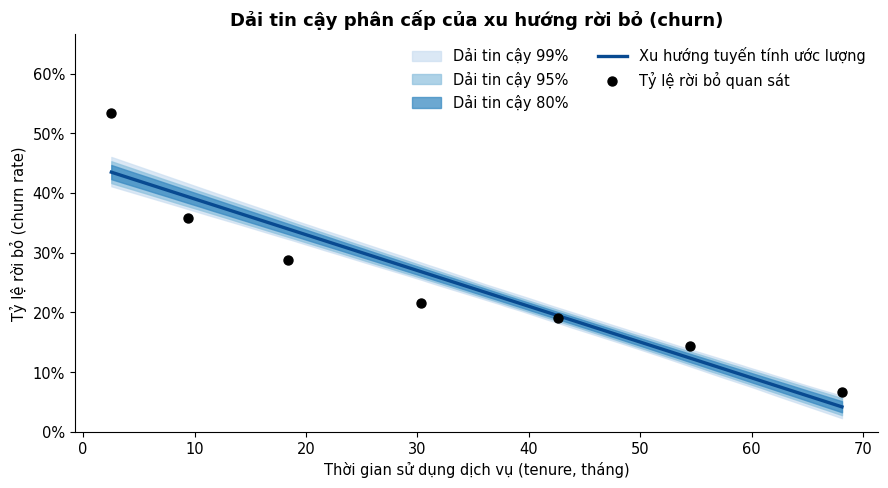


 KẾT LUẬN: Mức tin cậy càng cao thì dải càng rộng. Các dải phân cấp giúp thể hiện nhiều mức bất định, 
 thay vì coi dải 95% là một ranh giới tuyệt đối.


In [ ]:
from matplotlib.ticker import PercentFormatter

band_specs = [
    (0.99, plt.cm.Blues(0.22), 0.70),
    (0.95, plt.cm.Blues(0.42), 0.70),
    (0.80, plt.cm.Blues(0.65), 0.75)
]

fig, ax = plt.subplots(figsize=(9, 5))

for level, color, alpha in band_specs:
    tail = (1 - level) / 2
    lower, upper = np.quantile(
        curves_lin,
        [tail, 1 - tail],
        axis=0
    )

    ax.fill_between(
        grid,
        lower,
        upper,
        color=color,
        alpha=alpha,
        label=f'Dải tin cậy {int(level * 100)}%'
    )

ax.plot(
    grid,
    best,
    color=BLUE,
    linewidth=2.4,
    label='Xu hướng tuyến tính ước lượng'
)

ax.scatter(
    x, y,
    s=42,
    color='black',
    label='Tỷ lệ rời bỏ quan sát',
    zorder=4
)

ax.set_xlabel('Thời gian sử dụng dịch vụ (tenure, tháng)')
ax.set_ylabel('Tỷ lệ rời bỏ (churn rate)')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, min(1, max(y) * 1.25))

ax.set_title(
    'Dải tin cậy phân cấp của xu hướng rời bỏ (churn)'
)

ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.show()

print(
    "\n KẾT LUẬN: Mức tin cậy càng cao thì dải càng rộng. "
    "Các dải phân cấp giúp thể hiện nhiều mức bất định, \n thay vì "
    "coi dải 95% là một ranh giới tuyệt đối."
)

## Biểu đồ 18 — Non-linear fit + uncertainty (Figure 16.18)

**Có thể dùng trong Telco:** quan hệ tenure–churn có thể không hoàn toàn tuyến tính.

**Ví dụ vẽ:** polynomial bậc 3 trên các tenure bins + bootstrap band và 12 alternative curves.

> Đây là **demo trực quan**, không phải mô hình dự báo cuối cùng. Polynomial có thể “uốn” quá mức, đúng với cảnh báo của Wilke rằng uncertainty của non-linear fits còn bao gồm uncertainty về *shape*.

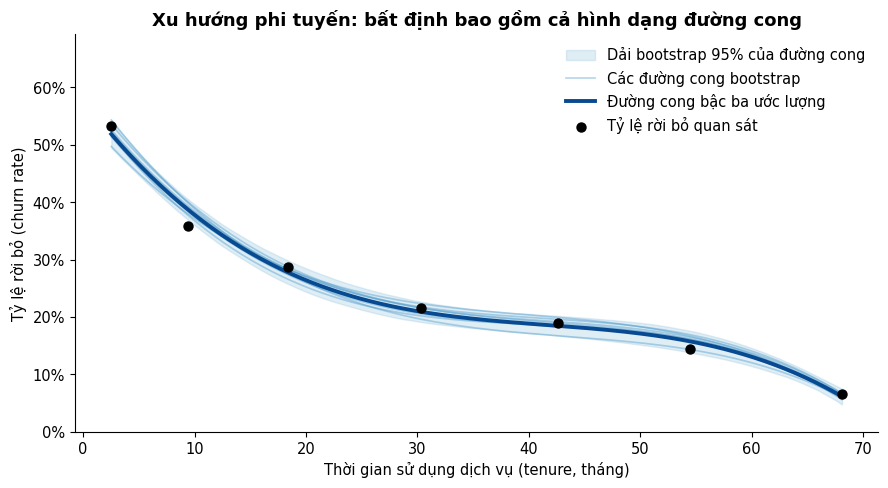


 KẾT LUẬN: Các đường cong không chỉ dịch chuyển lên hoặc xuống mà còn thay đổi độ uốn. Vì vậy, sự bất định 
 của mô hình phi tuyến còn bao gồm bất định về hình dạng đường.
 Lưu ý: Đây là minh họa trực quan bằng đa thức bậc ba, không phải mô hình dự báo cuối cùng.


In [ ]:
from matplotlib.ticker import PercentFormatter

grid3, curves3 = bootstrap_poly_curves(
    tb, degree=3, B=1800, seed=20
)

coef3 = np.polyfit(x, y, 3)
best3 = np.polyval(coef3, grid3)

lo3, hi3 = np.quantile(
    curves3,
    [0.025, 0.975],
    axis=0
)

rng_curves = np.random.default_rng(18)

sample_idx3 = rng_curves.choice(
    len(curves3),
    size=8,
    replace=False
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.fill_between(
    grid3,
    lo3,
    hi3,
    color=LIGHT,
    alpha=0.32,
    label='Dải bootstrap 95% của đường cong'
)

for i, curve in enumerate(curves3[sample_idx3]):
    ax.plot(
        grid3,
        curve,
        color=MID,
        linewidth=1.2,
        alpha=0.42,
        label='Các đường cong bootstrap' if i == 0 else None
    )

ax.plot(
    grid3,
    best3,
    color=BLUE,
    linewidth=2.8,
    label='Đường cong bậc ba ước lượng'
)

ax.scatter(
    x, y,
    color='black',
    s=42,
    label='Tỷ lệ rời bỏ quan sát',
    zorder=4
)

ax.set_xlabel('Thời gian sử dụng dịch vụ (tenure, tháng)')
ax.set_ylabel('Tỷ lệ rời bỏ (churn rate)')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, min(1, max(y) * 1.30))

ax.set_title(
    'Xu hướng phi tuyến: bất định bao gồm cả hình dạng đường cong'
)

ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(
    "\n KẾT LUẬN: Các đường cong không chỉ dịch chuyển "
    "lên hoặc xuống mà còn thay đổi độ uốn. Vì vậy, sự bất định \n "
    "của mô hình phi tuyến còn bao gồm bất định về hình dạng đường."
)

print(
    " Lưu ý: Đây là minh họa trực quan bằng đa thức bậc ba, "
    "không phải mô hình dự báo cuối cùng."
)

# Phần D — Hypothetical Outcome Plot (HOP)

## Biểu đồ 19 — HOP animation (Figures 16.19–16.22)

**Có thể dùng trong Telco:**
- Chiếu lần lượt các churn trend hợp lý theo tenure.
- Mỗi frame là một “kịch bản” khác nhưng vẫn tương thích với dữ liệu.
- Giúp tránh hiểu confidence band như một biên cứng.

**Ví dụ vẽ:** animation 20 bootstrap cubic curves. Trong slide, có thể chạy animation khoảng vài giây rồi dừng.

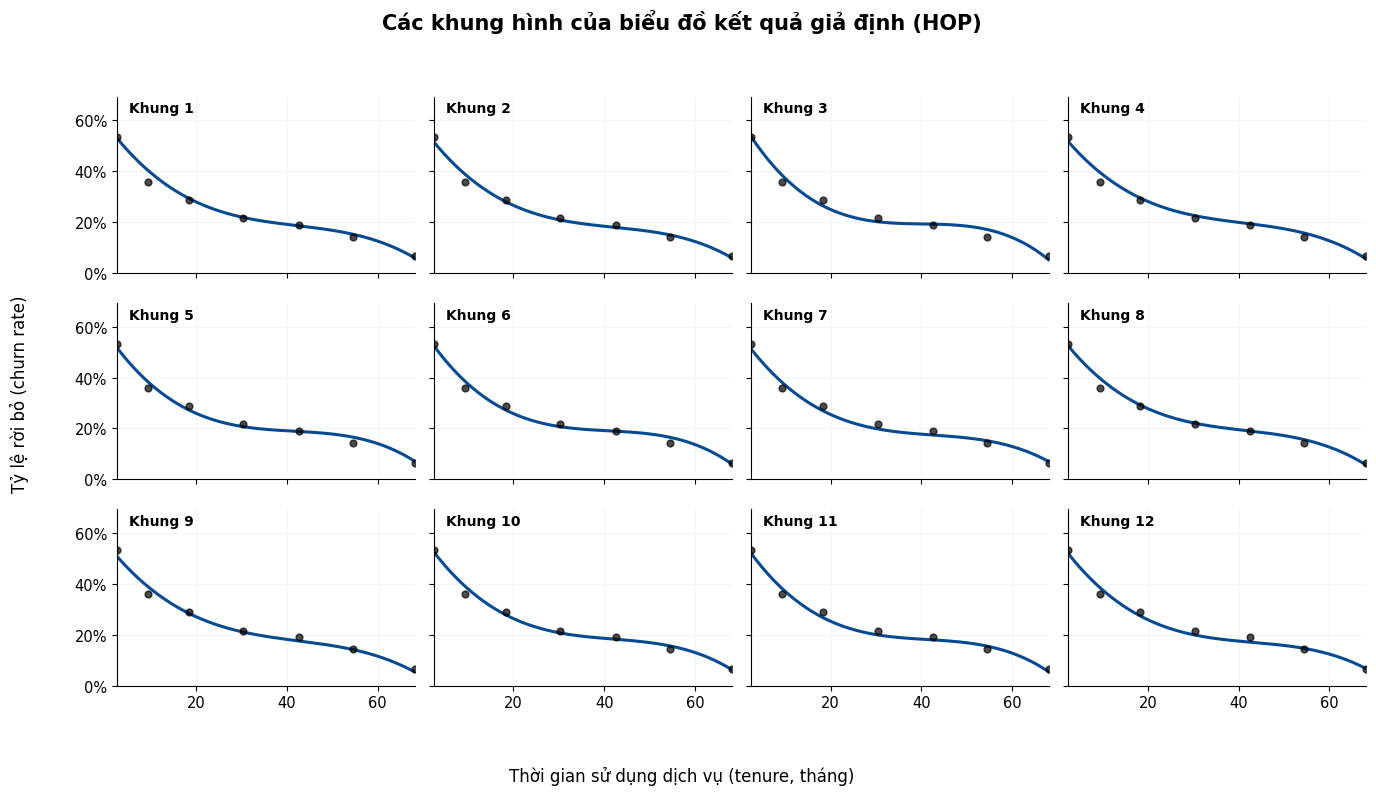

(Dành cho bản in)
 Mỗi khung hiển thị một đường xu hướng được sinh từ bootstrap. Trong HOP động, các khung này sẽ lần lượt 
 thay thế nhau thay vì xuất hiện đồng thời.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


rng_static_hop = np.random.default_rng(2026)

static_indices = rng_static_hop.choice(
    len(curves3),
    size=12,
    replace=False
)

static_hop_curves = curves3[static_indices]

# Bố cục 3 hàng × 4 cột
fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, (ax, curve) in enumerate(zip(axes, static_hop_curves)):

    # Các tỷ lệ rời bỏ quan sát theo nhóm tenure
    ax.scatter(
        x,
        y,
        color='black',
        s=24,
        alpha=0.70,
        zorder=3
    )

    # Một kết quả giả định trong mỗi khung
    ax.plot(
        grid3,
        curve,
        color=BLUE,
        linewidth=2.2
    )

    ax.set_xlim(grid3.min(), grid3.max())
    ax.set_ylim(0, min(1, max(y) * 1.30))

    ax.yaxis.set_major_formatter(PercentFormatter(1))

    ax.text(
        0.04,
        0.91,
        f'Khung {i + 1}',
        transform=ax.transAxes,
        fontsize=10,
        fontweight='bold'
    )

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(alpha=0.10)

# Nhãn chung cho toàn bộ hình
fig.supxlabel(
    'Thời gian sử dụng dịch vụ (tenure, tháng)',
    fontsize=12
)

fig.supylabel(
    'Tỷ lệ rời bỏ (churn rate)',
    fontsize=12
)

fig.suptitle(
    'Các khung hình của biểu đồ kết quả giả định (HOP)',
    fontsize=15,
    fontweight='bold',
    y=0.98
)

plt.tight_layout(
    rect=[0.03, 0.04, 1, 0.94],
    h_pad=1.4,
    w_pad=1.0
)

# Lưu ảnh để đưa vào báo cáo hoặc slide LaTeX
plt.savefig(
    'hop_frames_static.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print( "(Dành cho bản in)"
    "\n Mỗi khung hiển thị một đường xu hướng được sinh từ bootstrap. "
    "Trong HOP động, các khung này sẽ lần lượt \n thay thế nhau "
    "thay vì xuất hiện đồng thời."
)

In [ ]:
from matplotlib.animation import FuncAnimation
from matplotlib.ticker import PercentFormatter
from IPython.display import HTML, display

rng_hop = np.random.default_rng(19)

hop_curves = curves3[
    rng_hop.choice(
        len(curves3),
        size=20,
        replace=False
    )
]

fig, ax = plt.subplots(figsize=(8.5, 4.8))

ax.scatter(
    x, y,
    color='black',
    s=42,
    alpha=0.75,
    label='Tỷ lệ rời bỏ quan sát'
)

line, = ax.plot(
    [],
    [],
    color=BLUE,
    linewidth=2.8,
    label='Xu hướng bootstrap'
)

ax.set_xlim(grid3.min(), grid3.max())
ax.set_ylim(0, min(1, max(y) * 1.30))

ax.set_xlabel('Thời gian sử dụng dịch vụ (tenure, tháng)')
ax.set_ylabel('Tỷ lệ rời bỏ (churn rate)')
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_title(
    'HOP: Các xu hướng rời bỏ (churn) khả dĩ'
)

ax.legend(
    frameon=False,
    loc='upper right'
)

frame_text = ax.text(
    0.02,
    0.94,
    '',
    transform=ax.transAxes,
    fontsize=11
)

def init():
    line.set_data([], [])
    frame_text.set_text('')
    return line, frame_text

def update(i):
    line.set_data(grid3, hop_curves[i])
    frame_text.set_text(
        f'Kịch bản {i + 1}/{len(hop_curves)}'
    )
    return line, frame_text

ani = FuncAnimation(
    fig,
    update,
    frames=len(hop_curves),
    init_func=init,
    interval=650,
    blit=True,
    repeat=True
)

plt.close(fig)
display(HTML(ani.to_jshtml()))

print(
    "KẾT LUẬN: Mỗi khung hình là một đường xu hướng được sinh "
    "từ bootstrap. HOP giúp người xem cảm nhận sự bất định \n thông qua "
    "nhiều kết quả khả dĩ, thay vì xem dải tin cậy như một biên cứng."
)

KẾT LUẬN: Mỗi khung hình là một đường xu hướng được sinh từ bootstrap. HOP giúp người xem cảm nhận sự bất định 
 thông qua nhiều kết quả khả dĩ, thay vì xem dải tin cậy như một biên cứng.


# Phần E — Kết luận cho đề tài “Vì sao khách hàng rời bỏ và nên giữ chân ai?”

Với notebook này, phần thuyết trình nên kết luận ở mức **liên hệ + độ chắc chắn**:

1. Loại hợp đồng có liên hệ rất mạnh với churn rate trong dataset; hãy xem point estimate **cùng CI**.
2. Đừng ưu tiên một nhóm chỉ vì tỷ lệ churn cao nếu nhóm quá nhỏ và CI rất rộng.
3. Muốn so hai nhóm, nên xem **CI của chênh lệch** thay vì phán đoán bằng mắt từ hai error bars.
4. Tenure trend cũng là một ước lượng; confidence band/HOP cho thấy ta không biết chính xác “đường thật”.
5. **Retention action:** ưu tiên *xem xét* các segment vừa có churn cao vừa có quy mô đủ lớn; sau đó mới bổ sung giá trị kinh tế (MonthlyCharges/CLV, cost of offer) để quyết định chiến dịch.

Cell sau tạo một shortlist đơn giản, dùng **cận dưới 95% Wilson CI** để tránh xếp hạng quá mạnh các nhóm nhỏ.

In [ ]:
segment = (df.groupby(['Contract','PaymentMethod'])
             .agg(n=('Churn_bin','size'), churned=('Churn_bin','sum'),
                  churn_rate=('Churn_bin','mean'), avg_monthly=('MonthlyCharges','mean'))
             .reset_index())

cis = segment.apply(lambda r: wilson_ci(int(r['churned']), int(r['n']), .95), axis=1)
segment[['ci_low','ci_high']] = pd.DataFrame(cis.tolist(), index=segment.index)
segment['monthly_revenue_at_risk_proxy'] = segment['n'] * segment['churn_rate'] * segment['avg_monthly']

shortlist = (segment[segment['n'] >= 100]
             .sort_values(['ci_low','monthly_revenue_at_risk_proxy'], ascending=False)
             .head(8)
             [['Contract','PaymentMethod','n','churn_rate','ci_low','ci_high','avg_monthly','monthly_revenue_at_risk_proxy']])

shortlist.style.format({
    'churn_rate':'{:.1%}', 'ci_low':'{:.1%}', 'ci_high':'{:.1%}',
    'avg_monthly':'{:.2f}', 'monthly_revenue_at_risk_proxy':'{:,.0f}'
})

,Contract,PaymentMethod,n,churn_rate,ci_low,ci_high,avg_monthly,monthly_revenue_at_risk_proxy
2,Month-to-month,Electronic check,1850,53.7%,51.5%,56.0%,74.99,"74,540"
0,Month-to-month,Bank transfer (automatic),589,34.1%,30.4%,38.0%,69.09,"13,886"
1,Month-to-month,Credit card (automatic),543,32.8%,29.0%,36.8%,67.68,"12,047"
3,Month-to-month,Mailed check,893,31.6%,28.6%,34.7%,46.05,"12,986"
6,One year,Electronic check,347,18.4%,14.7%,22.9%,79.10,"5,062"
5,One year,Credit card (automatic),398,10.3%,7.7%,13.7%,67.97,"2,787"
4,One year,Bank transfer (automatic),391,9.7%,7.2%,13.1%,67.48,"2,564"
7,One year,Mailed check,336,6.8%,4.6%,10.1%,44.38,"1,021"


In [ ]:
top = shortlist.iloc[0]
print(
    "KẾT LUẬN CUỐI: một nhóm đáng ưu tiên kiểm tra cho retention là "
    f"{top['Contract']} + {top['PaymentMethod']} (n={int(top['n'])}, "
    f"churn={top['churn_rate']:.1%}, 95% CI=[{top['ci_low']:.1%}, {top['ci_high']:.1%}])."
)
print("Đây là ưu tiên mô tả dựa trên dữ liệu mẫu, chưa phải quyết định tối ưu kinh tế và không chứng minh nguyên nhân churn.")

KẾT LUẬN CUỐI: một nhóm đáng ưu tiên kiểm tra cho retention là Month-to-month + Electronic check (n=1850, churn=53.7%, 95% CI=[51.5%, 56.0%]).
Đây là ưu tiên mô tả dựa trên dữ liệu mẫu, chưa phải quyết định tối ưu kinh tế và không chứng minh nguyên nhân churn.
